# Project 3 Insurance Claim Dataset

**Mid-Term 2 – Khoa học dữ liệu**

GitHub của nhóm: https://github.com/duyta848-sys/Project3-Insurance-Claim

Chọn **Runtime → Run all**. CSV gốc được chứa nguyên văn trong ô đọc dữ liệu, nên notebook chạy độc lập khi mở từ GitHub hoặc tải trực tiếp lên Colab. Khi mở lại một phiên đã chạy, nên khởi động lại runtime trước Run all.

Bài dùng các thao tác trong tài liệu đã cung cấp. Phần giả thuyết đối chiếu các giả định với thống kê mô tả; không kết luận ý nghĩa thống kê bằng p-value. Các kết quả và biểu đồ được diễn giải ngay sau phần tương ứng.

Mã tương đương: `analysis.py`; CSV gốc: `Insurance.csv`; báo cáo chính thức: `Project3_MidTerm2_Report.pdf`.


## 01 Nhập thư viện

Sử dụng Pandas, NumPy, Matplotlib, Seaborn và các mô hình đã có trong bài thực hành tuần 15. Không cần cài thêm thư viện trên Colab thông thường.


In [1]:
# Nhập các thư viện đã dùng trong tài liệu học phần.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

# Đặt phông có dấu tiếng Việt và màu chữ của hình.
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['text.color'] = 'black'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'


## 02 Đọc dữ liệu gốc

Bộ dữ liệu gồm 1.338 dòng và 8 cột. Notebook chứa nguyên văn CSV gốc để chạy độc lập. StringIO có trong tài liệu T7 nhập và lưu trữ dữ liệu; read_csv có trong tài liệu T6. Khi chạy script trong bộ ZIP, dữ liệu được đọc từ Insurance.csv.


In [2]:
# Đọc nguyên văn CSV gốc bằng StringIO, không nén hoặc giải mã dữ liệu.
from io import StringIO

du_lieu_csv = """age,sex,bmi,children,smoker,region,charges,insuranceclaim
19,0,27.9,0,1,3,16884.924,1
18,1,33.77,1,0,2,1725.5523,1
28,1,33,3,0,2,4449.462,0
33,1,22.705,0,0,1,21984.47061,0
32,1,28.88,0,0,1,3866.8552,1
31,0,25.74,0,0,2,3756.6216,0
46,0,33.44,1,0,2,8240.5896,1
37,0,27.74,3,0,1,7281.5056,0
37,1,29.83,2,0,0,6406.4107,0
60,0,25.84,0,0,1,28923.13692,0
25,1,26.22,0,0,0,2721.3208,1
62,0,26.29,0,1,2,27808.7251,1
23,1,34.4,0,0,3,1826.843,1
56,0,39.82,0,0,2,11090.7178,1
27,1,42.13,0,1,2,39611.7577,1
19,1,24.6,1,0,3,1837.237,0
52,0,30.78,1,0,0,10797.3362,1
23,1,23.845,0,0,0,2395.17155,0
56,1,40.3,0,0,3,10602.385,1
30,1,35.3,0,1,3,36837.467,1
60,0,36.005,0,0,0,13228.84695,1
30,0,32.4,1,0,3,4149.736,1
18,1,34.1,0,0,2,1137.011,1
34,0,31.92,1,1,0,37701.8768,1
37,1,28.025,2,0,1,6203.90175,0
59,0,27.72,3,0,2,14001.1338,1
63,0,23.085,0,0,0,14451.83515,0
55,0,32.775,2,0,1,12268.63225,0
23,1,17.385,1,0,1,2775.19215,1
31,1,36.3,2,1,3,38711,1
22,1,35.6,0,1,3,35585.576,1
18,0,26.315,0,0,0,2198.18985,1
19,0,28.6,5,0,3,4687.797,0
63,1,28.31,0,0,1,13770.0979,1
28,1,36.4,1,1,3,51194.55914,1
19,1,20.425,0,0,1,1625.43375,0
62,0,32.965,3,0,1,15612.19335,0
26,1,20.8,0,0,3,2302.3,0
35,1,36.67,1,1,0,39774.2763,1
60,1,39.9,0,1,3,48173.361,1
24,0,26.6,0,0,0,3046.062,1
31,0,36.63,2,0,2,4949.7587,0
41,1,21.78,1,0,2,6272.4772,0
37,0,30.8,2,0,2,6313.759,0
38,1,37.05,1,0,0,6079.6715,0
55,1,37.3,0,0,3,20630.28351,1
18,0,38.665,2,0,0,3393.35635,0
28,0,34.77,0,0,1,3556.9223,1
60,0,24.53,0,0,2,12629.8967,0
36,1,35.2,1,1,2,38709.176,1
18,0,35.625,0,0,0,2211.13075,1
21,0,33.63,2,0,1,3579.8287,0
48,1,28,1,1,3,23568.272,1
36,1,34.43,0,1,2,37742.5757,1
40,0,28.69,3,0,1,8059.6791,0
58,1,36.955,2,1,1,47496.49445,1
58,0,31.825,2,0,0,13607.36875,0
18,1,31.68,2,1,2,34303.1672,1
53,0,22.88,1,1,2,23244.7902,1
34,0,37.335,2,0,1,5989.52365,0
43,1,27.36,3,0,0,8606.2174,1
25,1,33.66,4,0,2,4504.6624,0
64,1,24.7,1,0,1,30166.61817,0
28,0,25.935,1,0,1,4133.64165,0
20,0,22.42,0,1,1,14711.7438,1
19,0,28.9,0,0,3,1743.214,1
61,0,39.1,2,0,3,14235.072,1
40,1,26.315,1,0,1,6389.37785,0
40,0,36.19,0,0,2,5920.1041,1
28,1,23.98,3,1,2,17663.1442,0
27,0,24.75,0,1,2,16577.7795,1
31,1,28.5,5,0,0,6799.458,0
53,0,28.1,3,0,3,11741.726,1
58,1,32.01,1,0,2,11946.6259,1
44,1,27.4,2,0,3,7726.854,1
57,1,34.01,0,0,1,11356.6609,1
29,0,29.59,1,0,2,3947.4131,0
21,1,35.53,0,0,2,1532.4697,1
22,0,39.805,0,0,0,2755.02095,1
41,0,32.965,0,0,1,6571.02435,1
31,1,26.885,1,0,0,4441.21315,0
45,0,38.285,0,0,0,7935.29115,1
22,1,37.62,1,1,2,37165.1638,1
48,0,41.23,4,0,1,11033.6617,0
37,0,34.8,2,1,3,39836.519,1
45,1,22.895,2,1,1,21098.55405,1
57,0,31.16,0,1,1,43578.9394,1
56,0,27.2,0,0,3,11073.176,1
46,0,27.74,0,0,1,8026.6666,1
55,0,26.98,0,0,1,11082.5772,1
21,0,39.49,0,0,2,2026.9741,1
53,0,24.795,1,0,1,10942.13205,0
59,1,29.83,3,1,0,30184.9367,1
35,1,34.77,2,0,1,5729.0053,0
64,0,31.3,2,1,3,47291.055,1
28,0,37.62,1,0,2,3766.8838,0
54,0,30.8,3,0,3,12105.32,0
55,1,38.28,0,0,2,10226.2842,1
56,1,19.95,0,1,0,22412.6485,1
38,1,19.3,0,1,3,15820.699,1
41,0,31.6,0,0,3,6186.127,1
30,1,25.46,0,0,0,3645.0894,0
18,0,30.115,0,0,0,21344.8467,1
61,0,29.92,3,1,2,30942.1918,1
34,0,27.5,1,0,3,5003.853,0
20,1,28.025,1,1,1,17560.37975,1
19,0,28.4,1,0,3,2331.519,0
26,1,30.875,2,0,1,3877.30425,0
29,1,27.94,0,0,2,2867.1196,1
63,1,35.09,0,1,2,47055.5321,1
54,1,33.63,1,0,1,10825.2537,1
55,0,29.7,2,0,3,11881.358,1
37,1,30.8,0,0,3,4646.759,1
21,0,35.72,0,0,1,2404.7338,1
52,1,32.205,3,0,0,11488.31695,0
60,1,28.595,0,0,0,30259.99556,1
58,1,49.06,0,0,2,11381.3254,1
29,0,27.94,1,1,2,19107.7796,1
49,0,27.17,0,0,2,8601.3293,1
37,0,23.37,2,0,1,6686.4313,0
44,1,37.1,2,0,3,7740.337,1
18,1,23.75,0,0,0,1705.6245,0
20,0,28.975,0,0,1,2257.47525,1
44,1,31.35,1,1,0,39556.4945,1
47,0,33.915,3,0,1,10115.00885,0
26,0,28.785,0,0,0,3385.39915,1
19,0,28.3,0,1,3,17081.08,1
52,0,37.4,0,0,3,9634.538,1
32,0,17.765,2,1,1,32734.1863,0
38,1,34.7,2,0,3,6082.405,0
59,0,26.505,0,0,0,12815.44495,1
61,0,22.04,0,0,0,13616.3586,0
53,0,35.9,2,0,3,11163.568,1
19,1,25.555,0,0,1,1632.56445,0
20,0,28.785,0,0,0,2457.21115,1
22,0,28.05,0,0,2,2155.6815,1
19,1,34.1,0,0,3,1261.442,1
22,1,25.175,0,0,1,2045.68525,0
54,0,31.9,3,0,2,27322.73386,0
22,0,36,0,0,3,2166.732,1
34,1,22.42,2,0,0,27375.90478,0
26,1,32.49,1,0,0,3490.5491,1
34,1,25.3,2,1,2,18972.495,0
29,1,29.735,2,0,1,18157.876,0
30,1,28.69,3,1,1,20745.9891,0
29,0,38.83,3,0,2,5138.2567,0
46,1,30.495,3,1,1,40720.55105,1
51,0,37.73,1,0,2,9877.6077,1
53,0,37.43,1,0,1,10959.6947,1
19,1,28.4,1,0,3,1842.519,0
35,1,24.13,1,0,1,5125.2157,0
48,1,29.7,0,0,2,7789.635,1
32,0,37.145,3,0,0,6334.34355,0
42,0,23.37,0,1,0,19964.7463,1
40,0,25.46,1,0,0,7077.1894,0
44,1,39.52,0,0,1,6948.7008,1
48,1,24.42,0,1,2,21223.6758,1
18,1,25.175,0,1,0,15518.18025,1
30,1,35.53,0,1,2,36950.2567,1
50,0,27.83,3,0,2,19749.38338,1
42,0,26.6,0,1,1,21348.706,1
18,0,36.85,0,1,2,36149.4835,1
54,1,39.6,1,0,3,10450.552,1
32,0,29.8,2,0,3,5152.134,0
37,1,29.64,0,0,1,5028.1466,1
47,1,28.215,4,0,0,10407.08585,1
20,0,37,5,0,3,4830.63,0
32,0,33.155,3,0,1,6128.79745,0
19,0,31.825,1,0,1,2719.27975,1
27,1,18.905,3,0,0,4827.90495,0
63,1,41.47,0,0,2,13405.3903,1
49,1,30.3,0,0,3,8116.68,1
18,1,15.96,0,0,0,1694.7964,1
35,0,34.8,1,0,3,5246.047,1
24,0,33.345,0,0,1,2855.43755,1
63,0,37.7,0,1,3,48824.45,1
38,1,27.835,2,0,1,6455.86265,0
54,1,29.2,1,0,3,10436.096,0
46,0,28.9,2,0,3,8823.279,1
41,0,33.155,3,0,0,8538.28845,0
58,1,28.595,0,0,1,11735.87905,1
18,0,38.28,0,0,2,1631.8212,1
22,1,19.95,3,0,0,4005.4225,0
44,0,26.41,0,0,1,7419.4779,1
44,1,30.69,2,0,2,7731.4271,0
36,1,41.895,3,1,0,43753.33705,1
26,0,29.92,2,0,2,3981.9768,0
30,0,30.9,3,0,3,5325.651,0
41,0,32.2,1,0,3,6775.961,1
29,0,32.11,2,0,1,4922.9159,0
61,1,31.57,0,0,2,12557.6053,1
36,0,26.2,0,0,3,4883.866,1
25,1,25.74,0,0,2,2137.6536,0
56,0,26.6,1,0,1,12044.342,0
18,1,34.43,0,0,2,1137.4697,1
19,1,30.59,0,0,1,1639.5631,1
39,0,32.8,0,0,3,5649.715,1
45,0,28.6,2,0,2,8516.829,1
51,0,18.05,0,0,1,9644.2525,0
64,0,39.33,0,0,0,14901.5167,1
19,0,32.11,0,0,1,2130.6759,1
48,0,32.23,1,0,2,8871.1517,1
60,0,24.035,0,0,1,13012.20865,0
27,0,36.08,0,1,2,37133.8982,1
46,1,22.3,0,0,3,7147.105,0
28,0,28.88,1,0,0,4337.7352,0
59,1,26.4,0,0,2,11743.299,1
35,1,27.74,2,1,0,20984.0936,0
63,0,31.8,0,0,3,13880.949,1
40,1,41.23,1,0,0,6610.1097,1
20,1,33,1,0,3,1980.07,1
40,1,30.875,4,0,1,8162.71625,0
24,1,28.5,2,0,1,3537.703,0
34,0,26.73,1,0,2,5002.7827,0
45,0,30.9,2,0,3,8520.026,0
41,0,37.1,2,0,3,7371.772,1
53,0,26.6,0,0,1,10355.641,1
27,1,23.1,0,0,2,2483.736,0
26,0,29.92,1,0,2,3392.9768,0
24,0,23.21,0,0,2,25081.76784,0
34,0,33.7,1,0,3,5012.471,1
53,0,33.25,0,0,0,10564.8845,1
32,1,30.8,3,0,3,5253.524,0
19,1,34.8,0,1,3,34779.615,1
42,1,24.64,0,1,2,19515.5416,1
55,1,33.88,3,0,2,11987.1682,0
28,1,38.06,0,0,2,2689.4954,1
58,0,41.91,0,0,2,24227.33724,1
41,0,31.635,1,0,0,7358.17565,1
47,1,25.46,2,0,0,9225.2564,1
42,0,36.195,1,0,1,7443.64305,1
59,0,27.83,3,0,2,14001.2867,1
19,0,17.8,0,0,3,1727.785,0
59,1,27.5,1,0,3,12333.828,0
39,1,24.51,2,0,1,6710.1919,0
40,0,22.22,2,1,2,19444.2658,0
18,0,26.73,0,0,2,1615.7667,1
31,1,38.39,2,0,2,4463.2051,0
19,1,29.07,0,1,1,17352.6803,1
44,1,38.06,1,0,2,7152.6714,1
23,0,36.67,2,1,0,38511.6283,1
33,0,22.135,1,0,0,5354.07465,0
55,0,26.8,1,0,3,35160.13457,0
40,1,35.3,3,0,3,7196.867,0
63,0,27.74,0,1,0,29523.1656,1
54,1,30.02,0,0,1,24476.47851,1
60,0,38.06,0,0,2,12648.7034,1
24,1,35.86,0,0,2,1986.9334,1
19,1,20.9,1,0,3,1832.094,0
29,1,28.975,1,0,0,4040.55825,0
18,1,17.29,2,1,0,12829.4551,0
63,0,32.2,2,1,3,47305.305,1
54,1,34.21,2,1,2,44260.7499,1
27,1,30.3,3,0,3,4260.744,0
50,1,31.825,0,1,0,41097.16175,1
55,0,25.365,3,0,0,13047.33235,1
56,1,33.63,0,1,1,43921.1837,1
38,0,40.15,0,0,2,5400.9805,1
51,1,24.415,4,0,1,11520.09985,0
19,1,31.92,0,1,1,33750.2918,1
58,0,25.2,0,0,3,11837.16,0
20,0,26.84,1,1,2,17085.2676,1
52,1,24.32,3,1,0,24869.8368,1
19,1,36.955,0,1,1,36219.40545,1
53,0,38.06,3,0,2,20462.99766,0
46,1,42.35,3,1,2,46151.1245,1
40,1,19.8,1,1,2,17179.522,1
59,0,32.395,3,0,0,14590.63205,0
45,1,30.2,1,0,3,7441.053,1
49,1,25.84,1,0,0,9282.4806,0
18,1,29.37,1,0,2,1719.4363,0
50,1,34.2,2,1,3,42856.838,1
41,1,37.05,2,0,1,7265.7025,1
50,1,27.455,1,0,0,9617.66245,0
25,1,27.55,0,0,1,2523.1695,1
47,0,26.6,2,0,0,9715.841,1
19,1,20.615,2,0,1,2803.69785,0
22,0,24.3,0,0,3,2150.469,0
59,1,31.79,2,0,2,12928.7911,0
51,0,21.56,1,0,2,9855.1314,0
40,0,28.12,1,1,0,22331.5668,1
54,1,40.565,3,1,0,48549.17835,1
30,1,27.645,1,0,0,4237.12655,0
55,0,32.395,1,0,0,11879.10405,1
52,0,31.2,0,0,3,9625.92,1
46,1,26.62,1,0,2,7742.1098,0
46,0,48.07,2,0,0,9432.9253,1
63,0,26.22,0,0,1,14256.1928,1
59,0,36.765,1,1,0,47896.79135,1
52,1,26.4,3,0,2,25992.82104,1
28,0,33.4,0,0,3,3172.018,1
29,1,29.64,1,0,0,20277.80751,0
25,1,45.54,2,1,2,42112.2356,1
22,0,28.82,0,0,2,2156.7518,1
25,1,26.8,3,0,3,3906.127,0
18,1,22.99,0,0,0,1704.5681,0
19,1,27.7,0,1,3,16297.846,1
47,1,25.41,1,1,2,21978.6769,1
31,1,34.39,3,1,1,38746.3551,1
48,0,28.88,1,0,1,9249.4952,0
36,1,27.55,3,0,0,6746.7425,0
53,0,22.61,3,1,0,24873.3849,1
56,0,37.51,2,0,2,12265.5069,1
28,0,33,2,0,2,4349.462,0
57,0,38,2,0,3,12646.207,1
29,1,33.345,2,0,1,19442.3535,0
28,0,27.5,2,0,3,20177.67113,0
30,0,33.33,1,0,2,4151.0287,1
58,1,34.865,0,0,0,11944.59435,1
41,0,33.06,2,0,1,7749.1564,0
50,1,26.6,0,0,3,8444.474,1
19,0,24.7,0,0,3,1737.376,0
43,1,35.97,3,1,2,42124.5153,1
49,1,35.86,0,0,2,8124.4084,1
27,0,31.4,0,1,3,34838.873,1
52,1,33.25,0,0,0,9722.7695,1
50,1,32.205,0,0,1,8835.26495,1
54,1,32.775,0,0,0,10435.06525,1
44,0,27.645,0,0,1,7421.19455,1
32,1,37.335,1,0,0,4667.60765,0
34,1,25.27,1,0,1,4894.7533,0
26,0,29.64,4,0,0,24671.66334,0
34,1,30.8,0,1,3,35491.64,1
57,1,40.945,0,0,0,11566.30055,1
29,1,27.2,0,0,3,2866.091,1
40,1,34.105,1,0,0,6600.20595,1
27,0,23.21,1,0,2,3561.8889,0
45,1,36.48,2,1,1,42760.5022,1
64,0,33.8,1,1,3,47928.03,1
52,1,36.7,0,0,3,9144.565,1
61,0,36.385,1,1,0,48517.56315,1
52,1,27.36,0,1,1,24393.6224,1
61,0,31.16,0,0,1,13429.0354,1
56,0,28.785,0,0,0,11658.37915,1
43,0,35.72,2,0,0,19144.57652,1
64,1,34.5,0,0,3,13822.803,1
60,1,25.74,0,0,2,12142.5786,0
62,1,27.55,1,0,1,13937.6665,0
50,1,32.3,1,1,0,41919.097,1
46,0,27.72,1,0,2,8232.6388,0
24,0,27.6,0,0,3,18955.22017,1
62,1,30.02,0,0,1,13352.0998,1
60,0,27.55,0,0,0,13217.0945,1
63,1,36.765,0,0,0,13981.85035,1
49,0,41.47,4,0,2,10977.2063,0
34,0,29.26,3,0,2,6184.2994,0
33,1,35.75,2,0,2,4889.9995,0
46,1,33.345,1,0,0,8334.45755,1
36,0,29.92,1,0,2,5478.0368,0
19,1,27.835,0,0,1,1635.73365,1
57,0,23.18,0,0,1,11830.6072,0
50,0,25.6,0,0,3,8932.084,0
30,0,27.7,0,0,3,3554.203,1
33,1,35.245,0,0,0,12404.8791,1
18,0,38.28,0,0,2,14133.03775,1
46,1,27.6,0,0,3,24603.04837,1
46,1,43.89,3,0,2,8944.1151,0
47,1,29.83,3,0,1,9620.3307,1
23,1,41.91,0,0,2,1837.2819,1
18,0,20.79,0,0,2,1607.5101,0
48,0,32.3,2,0,0,10043.249,0
35,1,30.5,1,0,3,4751.07,0
19,0,21.7,0,1,3,13844.506,1
21,0,26.4,1,0,3,2597.779,0
21,0,21.89,2,0,2,3180.5101,0
49,0,30.78,1,0,0,9778.3472,1
56,0,32.3,3,0,0,13430.265,0
42,0,24.985,2,0,1,8017.06115,0
44,1,32.015,2,0,1,8116.26885,0
18,1,30.4,3,0,0,3481.868,0
61,0,21.09,0,0,1,13415.0381,0
57,0,22.23,0,0,0,12029.2867,0
42,0,33.155,1,0,0,7639.41745,1
26,1,32.9,2,1,3,36085.219,1
20,1,33.33,0,0,2,1391.5287,1
23,0,28.31,0,1,1,18033.9679,1
39,0,24.89,3,1,0,21659.9301,0
24,1,40.15,0,1,2,38126.2465,1
64,0,30.115,3,0,1,16455.70785,0
62,1,31.46,1,0,2,27000.98473,1
27,0,17.955,2,1,0,15006.57945,0
55,1,30.685,0,1,0,42303.69215,1
55,1,33,0,0,2,20781.48892,1
35,0,43.34,2,0,2,5846.9176,0
44,1,22.135,2,0,0,8302.53565,0
19,1,34.4,0,0,3,1261.859,1
58,0,39.05,0,0,2,11856.4115,1
50,1,25.365,2,0,1,30284.64294,1
26,0,22.61,0,0,1,3176.8159,0
24,0,30.21,3,0,1,4618.0799,0
48,1,35.625,4,0,0,10736.87075,0
19,0,37.43,0,0,1,2138.0707,1
48,1,31.445,1,0,0,8964.06055,1
49,1,31.35,1,0,0,9290.1395,1
46,0,32.3,2,0,0,9411.005,0
46,1,19.855,0,0,1,7526.70645,0
43,0,34.4,3,0,3,8522.003,0
21,1,31.02,0,0,2,16586.49771,1
64,1,25.6,2,0,3,14988.432,1
18,0,38.17,0,0,2,1631.6683,1
51,0,20.6,0,0,3,9264.797,0
47,1,47.52,1,0,2,8083.9198,1
64,0,32.965,0,0,1,14692.66935,1
49,1,32.3,3,0,1,10269.46,0
31,1,20.4,0,0,3,3260.199,0
52,0,38.38,2,0,0,11396.9002,1
33,0,24.31,0,0,2,4185.0979,0
47,0,23.6,1,0,3,8539.671,0
38,1,21.12,3,0,2,6652.5288,0
32,1,30.03,1,0,2,4074.4537,0
19,1,17.48,0,0,1,1621.3402,1
44,0,20.235,1,1,0,19594.80965,1
26,0,17.195,2,1,0,14455.64405,0
25,1,23.9,5,0,3,5080.096,0
19,0,35.15,0,0,1,2134.9015,1
43,0,35.64,1,0,2,7345.7266,1
52,1,34.1,0,0,2,9140.951,1
36,0,22.6,2,1,3,18608.262,0
64,1,39.16,1,0,2,14418.2804,1
63,0,26.98,0,1,1,28950.4692,1
64,1,33.88,0,1,2,46889.2612,1
61,1,35.86,0,1,2,46599.1084,1
40,1,32.775,1,1,0,39125.33225,1
25,1,30.59,0,0,0,2727.3951,1
48,1,30.2,2,0,3,8968.33,0
45,1,24.31,5,0,2,9788.8659,0
38,0,27.265,1,0,0,6555.07035,0
18,0,29.165,0,0,0,7323.734819,1
21,0,16.815,1,0,0,3167.45585,1
27,0,30.4,3,0,1,18804.7524,0
19,1,33.1,0,0,3,23082.95533,1
29,0,20.235,2,0,1,4906.40965,0
42,1,26.9,0,0,3,5969.723,1
60,0,30.5,0,0,3,12638.195,1
31,1,28.595,1,0,1,4243.59005,0
60,1,33.11,3,0,2,13919.8229,0
22,1,31.73,0,0,0,2254.7967,1
35,1,28.9,3,0,3,5926.846,0
52,0,46.75,5,0,2,12592.5345,1
26,1,29.45,0,0,0,2897.3235,1
31,0,32.68,1,0,1,4738.2682,1
33,0,33.5,0,1,3,37079.372,1
18,1,43.01,0,0,2,1149.3959,1
59,0,36.52,1,0,2,28287.89766,1
56,1,26.695,1,1,1,26109.32905,1
45,0,33.1,0,0,3,7345.084,1
60,1,29.64,0,0,0,12730.9996,1
56,0,25.65,0,0,1,11454.0215,0
40,0,29.6,0,0,3,5910.944,1
35,1,38.6,1,0,3,4762.329,0
39,1,29.6,4,0,3,7512.267,0
30,1,24.13,1,0,1,4032.2407,0
24,1,23.4,0,0,3,1969.614,0
20,1,29.735,0,0,1,1769.53165,1
32,1,46.53,2,0,2,4686.3887,1
59,1,37.4,0,0,3,21797.0004,1
55,0,30.14,2,0,2,11881.9696,0
57,0,30.495,0,0,1,11840.77505,1
56,1,39.6,0,0,3,10601.412,1
40,0,33,3,0,2,7682.67,0
49,0,36.63,3,0,2,10381.4787,0
42,1,30,0,1,3,22144.032,1
62,0,38.095,2,0,0,15230.32405,1
56,1,25.935,0,0,0,11165.41765,0
19,1,25.175,0,0,1,1632.03625,0
30,0,28.38,1,1,2,19521.9682,1
60,0,28.7,1,0,3,13224.693,0
56,0,33.82,2,0,1,12643.3778,0
28,0,24.32,1,0,0,23288.9284,0
18,0,24.09,1,0,2,2201.0971,0
27,1,32.67,0,0,2,2497.0383,1
18,0,30.115,0,0,0,2203.47185,1
19,0,29.8,0,0,3,1744.465,1
47,0,33.345,0,0,0,20878.78443,1
54,1,25.1,3,1,3,25382.297,1
61,1,28.31,1,1,1,28868.6639,1
24,1,28.5,0,1,0,35147.52848,1
25,1,35.625,0,0,1,2534.39375,1
21,1,36.85,0,0,2,1534.3045,1
23,1,32.56,0,0,2,1824.2854,1
63,1,41.325,3,0,1,15555.18875,0
49,1,37.51,2,0,2,9304.7019,1
18,0,31.35,0,0,2,1622.1885,1
51,0,39.5,1,0,3,9880.068,1
48,1,34.3,3,0,3,9563.029,0
31,0,31.065,0,0,0,4347.02335,1
54,0,21.47,3,0,1,12475.3513,0
19,1,28.7,0,0,3,1253.936,1
44,0,38.06,0,1,2,48885.13561,1
53,1,31.16,1,0,1,10461.9794,1
19,0,32.9,0,0,3,1748.774,1
61,0,25.08,0,0,2,24513.09126,0
18,0,25.08,0,0,0,2196.4732,0
61,1,43.4,0,0,3,12574.049,1
21,1,25.7,4,1,3,17942.106,0
20,1,27.93,0,0,0,1967.0227,1
31,0,23.6,2,0,3,4931.647,0
45,1,28.7,2,0,3,8027.968,1
44,0,23.98,2,0,2,8211.1002,0
62,0,39.2,0,0,3,13470.86,1
29,1,34.4,0,1,3,36197.699,1
43,1,26.03,0,0,0,6837.3687,1
51,1,23.21,1,1,2,22218.1149,1
19,1,30.25,0,1,2,32548.3405,1
38,0,28.93,1,0,2,5974.3847,0
37,1,30.875,3,0,1,6796.86325,0
22,1,31.35,1,0,1,2643.2685,1
21,1,23.75,2,0,1,3077.0955,0
24,0,25.27,0,0,0,3044.2133,0
57,0,28.7,0,0,3,11455.28,1
56,1,32.11,1,0,0,11763.0009,1
27,1,33.66,0,0,2,2498.4144,1
51,1,22.42,0,0,0,9361.3268,0
19,1,30.4,0,0,3,1256.299,1
39,1,28.3,1,1,3,21082.16,1
58,1,35.7,0,0,3,11362.755,1
20,1,35.31,1,0,2,27724.28875,0
45,1,30.495,2,0,1,8413.46305,0
35,0,31,1,0,3,5240.765,0
31,1,30.875,0,0,0,3857.75925,1
50,0,27.36,0,0,0,25656.57526,1
32,0,44.22,0,0,2,3994.1778,1
51,0,33.915,0,0,0,9866.30485,1
38,0,37.73,0,0,2,5397.6167,1
42,1,26.07,1,1,2,38245.59327,1
18,0,33.88,0,0,2,11482.63485,1
19,0,30.59,2,0,1,24059.68019,0
51,0,25.8,1,0,3,9861.025,0
46,1,39.425,1,0,0,8342.90875,1
18,1,25.46,0,0,0,1708.0014,0
57,1,42.13,1,1,2,48675.5177,1
62,0,31.73,0,0,0,14043.4767,1
59,1,29.7,2,0,2,12925.886,1
37,1,36.19,0,0,2,19214.70553,1
64,1,40.48,0,0,2,13831.1152,1
38,1,28.025,1,0,0,6067.12675,0
33,0,38.9,3,0,3,5972.378,0
46,0,30.2,2,0,3,8825.086,0
46,0,28.05,1,0,2,8233.0975,0
53,1,31.35,0,0,2,27346.04207,1
34,0,38,3,0,3,6196.448,0
20,0,31.79,2,0,2,3056.3881,0
63,0,36.3,0,0,2,13887.204,1
54,0,47.41,0,1,2,63770.42801,1
54,1,30.21,0,0,1,10231.4999,1
49,1,25.84,2,1,1,23807.2406,1
28,1,35.435,0,0,0,3268.84665,1
54,0,46.7,2,0,3,11538.421,1
25,0,28.595,0,0,0,3213.62205,1
43,0,46.2,0,1,2,45863.205,1
63,1,30.8,0,0,3,13390.559,1
32,0,28.93,0,0,2,3972.9247,1
62,1,21.4,0,0,3,12957.118,0
52,0,31.73,2,0,1,11187.6567,0
25,0,41.325,0,0,0,17878.90068,1
28,1,23.8,2,0,3,3847.674,0
46,1,33.44,1,0,0,8334.5896,1
34,1,34.21,0,0,2,3935.1799,1
35,0,34.105,3,1,1,39983.42595,1
19,1,35.53,0,0,1,1646.4297,1
46,0,19.95,2,0,1,9193.8385,0
54,0,32.68,0,0,0,10923.9332,1
27,1,30.5,0,0,3,2494.022,1
50,1,44.77,1,0,2,9058.7303,1
18,0,32.12,2,0,2,2801.2588,0
19,0,30.495,0,0,1,2128.43105,1
38,0,40.565,1,0,1,6373.55735,1
41,1,30.59,2,0,1,7256.7231,0
49,0,31.9,5,0,3,11552.904,0
48,1,40.565,2,1,1,45702.02235,1
31,0,29.1,0,0,3,3761.292,1
18,0,37.29,1,0,2,2219.4451,0
30,0,43.12,2,0,2,4753.6368,0
62,0,36.86,1,0,0,31620.00106,1
57,0,34.295,2,0,0,13224.05705,0
58,0,27.17,0,0,1,12222.8983,1
22,1,26.84,0,0,2,1664.9996,1
31,0,38.095,1,1,0,58571.07448,1
52,1,30.2,1,0,3,9724.53,1
25,0,23.465,0,0,0,3206.49135,0
59,1,25.46,1,0,0,12913.9924,0
19,1,30.59,0,0,1,1639.5631,1
39,1,45.43,2,0,2,6356.2707,1
32,0,23.65,1,0,2,17626.23951,0
19,1,20.7,0,0,3,1242.816,0
33,0,28.27,1,0,2,4779.6023,0
21,1,20.235,3,0,0,3861.20965,0
34,0,30.21,1,1,1,43943.8761,1
61,0,35.91,0,0,0,13635.6379,1
38,0,30.69,1,0,2,5976.8311,0
58,0,29,0,0,3,11842.442,1
47,1,19.57,1,0,1,8428.0693,0
20,1,31.13,2,0,2,2566.4707,0
21,0,21.85,1,1,0,15359.1045,1
41,1,40.26,0,0,2,5709.1644,1
46,0,33.725,1,0,0,8823.98575,1
42,0,29.48,2,0,2,7640.3092,1
34,0,33.25,1,0,0,5594.8455,1
43,1,32.6,2,0,3,7441.501,0
52,0,37.525,2,0,1,33471.97189,1
18,0,39.16,0,0,2,1633.0444,1
51,1,31.635,0,0,1,9174.13565,1
56,0,25.3,0,0,3,11070.535,0
64,0,39.05,3,0,2,16085.1275,0
19,0,28.31,0,1,1,17468.9839,1
51,0,34.1,0,0,2,9283.562,1
27,0,25.175,0,0,0,3558.62025,0
59,0,23.655,0,1,1,25678.77845,1
28,1,26.98,2,0,0,4435.0942,0
30,1,37.8,2,1,3,39241.442,1
47,0,29.37,1,0,2,8547.6913,0
38,0,34.8,2,0,3,6571.544,0
18,0,33.155,0,0,0,2207.69745,1
34,0,19,3,0,0,6753.038,0
20,0,33,0,0,2,1880.07,1
47,0,36.63,1,1,2,42969.8527,1
56,0,28.595,0,0,0,11658.11505,1
49,1,25.6,2,1,3,23306.547,1
19,0,33.11,0,1,2,34439.8559,1
55,0,37.1,0,0,3,10713.644,1
30,1,31.4,1,0,3,3659.346,1
37,1,34.1,4,1,3,40182.246,1
49,0,21.3,1,0,3,9182.17,0
18,1,33.535,0,1,0,34617.84065,1
59,1,28.785,0,0,1,12129.61415,1
29,0,26.03,0,0,1,3736.4647,1
36,1,28.88,3,0,0,6748.5912,0
33,1,42.46,1,0,2,11326.71487,1
58,1,38,0,0,3,11365.952,1
44,0,38.95,0,1,1,42983.4585,1
53,1,36.1,1,0,3,10085.846,1
24,1,29.3,0,0,3,1977.815,1
29,0,35.53,0,0,2,3366.6697,1
40,1,22.705,2,0,0,7173.35995,0
51,1,39.7,1,0,3,9391.346,1
64,1,38.19,0,0,0,14410.9321,1
19,0,24.51,1,0,1,2709.1119,0
35,0,38.095,2,0,0,24915.04626,0
39,1,26.41,0,1,0,20149.3229,1
56,1,33.66,4,0,2,12949.1554,0
33,1,42.4,5,0,3,6666.243,0
42,1,28.31,3,1,1,32787.45859,0
61,1,33.915,0,0,0,13143.86485,1
23,0,34.96,3,0,1,4466.6214,0
43,1,35.31,2,0,2,18806.14547,1
48,1,30.78,3,0,0,10141.1362,0
39,1,26.22,1,0,1,6123.5688,0
40,0,23.37,3,0,0,8252.2843,0
18,1,28.5,0,0,0,1712.227,1
58,0,32.965,0,0,0,12430.95335,1
49,0,42.68,2,0,2,9800.8882,0
53,0,39.6,1,0,2,10579.711,1
48,0,31.13,0,0,2,8280.6227,1
45,0,36.3,2,0,2,8527.532,1
59,0,35.2,0,0,2,12244.531,1
52,0,25.3,2,1,2,24667.419,1
26,0,42.4,1,0,3,3410.324,1
27,1,33.155,2,0,1,4058.71245,0
48,0,35.91,1,0,0,26392.26029,1
57,0,28.785,4,0,0,14394.39815,1
37,1,46.53,3,0,2,6435.6237,1
57,0,23.98,1,0,2,22192.43711,0
32,0,31.54,1,0,0,5148.5526,1
18,1,33.66,0,0,2,1136.3994,1
64,0,22.99,0,1,2,27037.9141,1
43,1,38.06,2,1,2,42560.4304,1
49,1,28.7,1,0,3,8703.456,0
40,0,32.775,2,1,1,40003.33225,1
62,1,32.015,0,1,0,45710.20785,1
40,0,29.81,1,0,2,6500.2359,0
30,1,31.57,3,0,2,4837.5823,0
29,0,31.16,0,0,0,3943.5954,1
36,1,29.7,0,0,2,4399.731,1
41,0,31.02,0,0,2,6185.3208,1
44,0,43.89,2,1,2,46200.9851,1
45,1,21.375,0,0,1,7222.78625,0
55,0,40.81,3,0,2,12485.8009,0
60,1,31.35,3,1,1,46130.5265,1
56,1,36.1,3,0,3,12363.547,0
49,0,23.18,2,0,1,10156.7832,0
21,0,17.4,1,0,3,2585.269,1
19,1,20.3,0,0,3,1242.26,0
39,1,35.3,2,1,3,40103.89,1
53,1,24.32,0,0,1,9863.4718,0
33,0,18.5,1,0,3,4766.022,0
53,1,26.41,2,0,0,11244.3769,1
42,1,26.125,2,0,0,7729.64575,1
40,1,41.69,0,0,2,5438.7491,1
47,0,24.1,1,0,3,26236.57997,0
27,1,31.13,1,1,2,34806.4677,1
21,1,27.36,0,0,0,2104.1134,1
47,1,36.2,1,0,3,8068.185,1
20,1,32.395,1,0,1,2362.22905,1
24,1,23.655,0,0,1,2352.96845,0
27,0,34.8,1,0,3,3577.999,1
26,0,40.185,0,0,1,3201.24515,1
53,0,32.3,2,0,0,29186.48236,0
41,1,35.75,1,1,2,40273.6455,1
56,1,33.725,0,0,1,10976.24575,1
23,0,39.27,2,0,2,3500.6123,0
21,0,34.87,0,0,2,2020.5523,1
50,0,44.745,0,0,0,9541.69555,1
53,1,41.47,0,0,2,9504.3103,1
34,0,26.41,1,0,1,5385.3379,0
47,0,29.545,1,0,1,8930.93455,0
33,0,32.9,2,0,3,5375.038,0
51,0,38.06,0,1,2,44400.4064,1
49,1,28.69,3,0,1,10264.4421,1
31,0,30.495,3,0,0,6113.23105,0
36,0,27.74,0,0,0,5469.0066,1
18,1,35.2,1,0,2,1727.54,0
50,0,23.54,2,0,2,10107.2206,0
43,0,30.685,2,0,1,8310.83915,0
20,1,40.47,0,0,0,1984.4533,1
24,0,22.6,0,0,3,2457.502,0
60,1,28.9,0,0,3,12146.971,1
49,0,22.61,1,0,1,9566.9909,0
60,1,24.32,1,0,1,13112.6048,0
51,0,36.67,2,0,1,10848.1343,1
58,0,33.44,0,0,1,12231.6136,1
51,0,40.66,0,0,0,9875.6804,1
53,1,36.6,3,0,3,11264.541,0
62,1,37.4,0,0,3,12979.358,1
19,1,35.4,0,0,3,1263.249,1
50,0,27.075,1,0,0,10106.13425,0
30,0,39.05,3,1,2,40932.4295,1
41,1,28.405,1,0,1,6664.68595,0
29,0,21.755,1,1,0,16657.71745,1
18,0,40.28,0,0,0,2217.6012,1
41,0,36.08,1,0,2,6781.3542,1
35,1,24.42,3,1,2,19361.9988,0
53,1,21.4,1,0,3,10065.413,0
24,0,30.1,3,0,3,4234.927,0
48,0,27.265,1,0,0,9447.25035,0
59,0,32.1,3,0,3,14007.222,0
49,0,34.77,1,0,1,9583.8933,1
37,0,38.39,0,1,2,40419.0191,1
26,1,23.7,2,0,3,3484.331,0
23,1,31.73,3,1,0,36189.1017,1
29,1,35.5,2,1,3,44585.45587,1
45,1,24.035,2,0,0,8604.48365,0
27,1,29.15,0,1,2,18246.4955,1
53,1,34.105,0,1,0,43254.41795,1
31,0,26.62,0,0,2,3757.8448,1
50,1,26.41,0,0,1,8827.2099,1
50,0,30.115,1,0,1,9910.35985,1
34,1,27,2,0,3,11737.84884,0
19,1,21.755,0,0,1,1627.28245,0
47,0,36,1,0,3,8556.907,1
28,1,30.875,0,0,1,3062.50825,1
37,0,26.4,0,1,2,19539.243,1
21,1,28.975,0,0,1,1906.35825,1
64,1,37.905,0,0,1,14210.53595,1
58,0,22.77,0,0,2,11833.7823,0
24,1,33.63,4,0,0,17128.42608,0
31,1,27.645,2,0,0,5031.26955,0
39,0,22.8,3,0,0,7985.815,0
47,0,27.83,0,1,2,23065.4207,1
30,1,37.43,3,0,0,5428.7277,0
18,1,38.17,0,1,2,36307.7983,1
22,0,34.58,2,0,0,3925.7582,0
23,1,35.2,1,0,3,2416.955,0
33,1,27.1,1,1,3,19040.876,1
27,1,26.03,0,0,0,3070.8087,1
45,0,25.175,2,0,0,9095.06825,1
57,0,31.825,0,0,1,11842.62375,1
47,1,32.3,1,0,3,8062.764,1
42,0,29,1,0,3,7050.642,0
64,0,39.7,0,0,3,14319.031,1
38,0,19.475,2,0,1,6933.24225,0
61,1,36.1,3,0,3,27941.28758,0
53,0,26.7,2,0,3,11150.78,1
44,0,36.48,0,0,0,12797.20962,1
19,0,28.88,0,1,1,17748.5062,1
41,1,34.2,2,0,1,7261.741,0
51,1,33.33,3,0,2,10560.4917,0
40,1,32.3,2,0,1,6986.697,0
45,1,39.805,0,0,0,7448.40395,1
35,1,34.32,3,0,2,5934.3798,0
53,1,28.88,0,0,1,9869.8102,1
30,1,24.4,3,1,3,18259.216,0
18,1,41.14,0,0,2,1146.7966,1
51,1,35.97,1,0,2,9386.1613,1
50,0,27.6,1,1,3,24520.264,1
31,0,29.26,1,0,2,4350.5144,0
35,0,27.7,3,0,3,6414.178,0
60,1,36.955,0,0,0,12741.16745,1
21,1,36.86,0,0,1,1917.3184,1
29,1,22.515,3,0,0,5209.57885,0
62,0,29.92,0,0,2,13457.9608,1
39,0,41.8,0,0,2,5662.225,1
19,1,27.6,0,0,3,1252.407,1
22,0,23.18,0,0,0,2731.9122,0
53,1,20.9,0,1,2,21195.818,1
39,0,31.92,2,0,1,7209.4918,0
27,1,28.5,0,1,1,18310.742,1
30,1,44.22,2,0,2,4266.1658,0
30,0,22.895,1,0,0,4719.52405,0
58,0,33.1,0,0,3,11848.141,1
33,1,24.795,0,1,0,17904.52705,1
42,0,26.18,1,0,2,7046.7222,0
64,0,35.97,0,0,2,14313.8463,1
21,1,22.3,1,0,3,2103.08,0
18,0,42.24,0,1,2,38792.6856,1
23,1,26.51,0,0,2,1815.8759,1
45,0,35.815,0,0,1,7731.85785,1
40,0,41.42,1,0,1,28476.73499,1
19,0,36.575,0,0,1,2136.88225,1
18,1,30.14,0,0,2,1131.5066,1
25,1,25.84,1,0,0,3309.7926,0
46,0,30.8,3,0,3,9414.92,0
33,0,42.94,3,0,1,6360.9936,0
54,1,21.01,2,0,2,11013.7119,0
28,1,22.515,2,0,0,4428.88785,0
36,1,34.43,2,0,2,5584.3057,0
20,0,31.46,0,0,2,1877.9294,1
24,0,24.225,0,0,1,2842.76075,0
23,1,37.1,3,0,3,3597.596,0
47,0,26.125,1,1,0,23401.30575,1
33,0,35.53,0,1,1,55135.40209,1
45,1,33.7,1,0,3,7445.918,1
26,1,17.67,0,0,1,2680.9493,0
18,0,31.13,0,0,2,1621.8827,1
44,0,29.81,2,0,2,8219.2039,1
60,1,24.32,0,0,1,12523.6048,0
64,0,31.825,2,0,0,16069.08475,0
56,1,31.79,2,1,2,43813.8661,1
36,1,28.025,1,1,0,20773.62775,1
41,1,30.78,3,1,0,39597.4072,1
39,1,21.85,1,0,1,6117.4945,0
63,1,33.1,0,0,3,13393.756,1
36,0,25.84,0,0,1,5266.3656,0
28,0,23.845,2,0,1,4719.73655,0
58,1,34.39,0,0,1,11743.9341,1
36,1,33.82,1,0,1,5377.4578,1
42,1,35.97,2,0,2,7160.3303,1
36,1,31.5,0,0,3,4402.233,1
56,0,28.31,0,0,0,11657.7189,1
35,0,23.465,2,0,0,6402.29135,0
59,0,31.35,0,0,1,12622.1795,1
21,1,31.1,0,0,3,1526.312,1
59,1,24.7,0,0,0,12323.936,0
23,0,32.78,2,1,2,36021.0112,1
57,0,29.81,0,1,2,27533.9129,1
53,1,30.495,0,0,0,10072.05505,1
60,0,32.45,0,1,2,45008.9555,1
51,0,34.2,1,0,3,9872.701,1
23,1,50.38,1,0,2,2438.0552,1
27,0,24.1,0,0,3,2974.126,0
55,1,32.775,0,0,1,10601.63225,1
37,0,30.78,0,1,0,37270.1512,1
61,1,32.3,2,0,1,14119.62,0
46,0,35.53,0,1,0,42111.6647,1
53,0,23.75,2,0,0,11729.6795,0
49,0,23.845,3,1,0,24106.91255,1
20,0,29.6,0,0,3,1875.344,1
48,0,33.11,0,1,2,40974.1649,1
25,1,24.13,0,1,1,15817.9857,1
25,0,32.23,1,0,2,18218.16139,1
57,1,28.1,0,0,3,10965.446,1
37,0,47.6,2,1,3,46113.511,1
38,0,28,3,0,3,7151.092,0
55,0,33.535,2,0,1,12269.68865,0
36,0,19.855,0,0,0,5458.04645,0
51,1,25.4,0,0,3,8782.469,0
40,1,29.9,2,0,3,6600.361,0
18,1,37.29,0,0,2,1141.4451,1
57,1,43.7,1,0,3,11576.13,1
61,1,23.655,0,0,0,13129.60345,0
25,0,24.3,3,0,3,4391.652,0
50,1,36.2,0,0,3,8457.818,1
26,0,29.48,1,0,2,3392.3652,0
42,1,24.86,0,0,2,5966.8874,0
43,1,30.1,1,0,3,6849.026,1
44,1,21.85,3,0,0,8891.1395,0
23,0,28.12,0,0,1,2690.1138,1
49,0,27.1,1,0,3,26140.3603,0
33,1,33.44,5,0,2,6653.7886,0
41,1,28.8,1,0,3,6282.235,0
37,0,29.5,2,0,3,6311.952,0
22,1,34.8,3,0,3,3443.064,0
23,1,27.36,1,0,1,2789.0574,0
21,0,22.135,0,0,0,2585.85065,0
51,0,37.05,3,1,0,46255.1125,1
25,1,26.695,4,0,1,4877.98105,0
32,1,28.93,1,1,2,19719.6947,1
57,1,28.975,0,1,0,27218.43725,1
36,0,30.02,0,0,1,5272.1758,1
22,1,39.5,0,0,3,1682.597,1
57,1,33.63,1,0,1,11945.1327,1
64,0,26.885,0,1,1,29330.98315,1
36,0,29.04,4,0,2,7243.8136,0
54,1,24.035,0,0,0,10422.91665,0
47,1,38.94,2,1,2,44202.6536,1
62,1,32.11,0,0,0,13555.0049,1
61,0,44,0,0,3,13063.883,1
43,0,20.045,2,1,0,19798.05455,1
19,1,25.555,1,0,1,2221.56445,0
18,0,40.26,0,0,2,1634.5734,1
19,0,22.515,0,0,1,2117.33885,0
49,1,22.515,0,0,0,8688.85885,0
60,1,40.92,0,1,2,48673.5588,1
26,1,27.265,3,0,0,4661.28635,0
49,1,36.85,0,0,2,8125.7845,1
60,0,35.1,0,0,3,12644.589,1
26,0,29.355,2,0,0,4564.19145,0
27,1,32.585,3,0,0,4846.92015,0
44,0,32.34,1,0,2,7633.7206,1
63,1,39.8,3,0,3,15170.069,0
32,0,24.6,0,1,3,17496.306,1
22,1,28.31,1,0,1,2639.0429,0
18,1,31.73,0,1,0,33732.6867,1
59,0,26.695,3,0,1,14382.70905,1
44,0,27.5,1,0,3,7626.993,0
33,1,24.605,2,0,1,5257.50795,0
24,0,33.99,0,0,2,2473.3341,1
43,0,26.885,0,1,1,21774.32215,1
45,1,22.895,0,1,0,35069.37452,1
61,0,28.2,0,0,3,13041.921,1
35,0,34.21,1,0,2,5245.2269,1
62,0,25,0,0,3,13451.122,0
62,0,33.2,0,0,3,13462.52,1
38,1,31,1,0,3,5488.262,0
34,1,35.815,0,0,1,4320.41085,1
43,1,23.2,0,0,3,6250.435,0
50,1,32.11,2,0,0,25333.33284,0
19,0,23.4,2,0,3,2913.569,0
57,0,20.1,1,0,3,12032.326,0
62,0,39.16,0,0,2,13470.8044,1
41,1,34.21,1,0,2,6289.7549,1
26,1,46.53,1,0,2,2927.0647,1
39,0,32.5,1,0,3,6238.298,1
46,1,25.8,5,0,3,10096.97,1
45,0,35.3,0,0,3,7348.142,1
32,1,37.18,2,0,2,4673.3922,0
59,0,27.5,0,0,3,12233.828,1
44,1,29.735,2,0,0,32108.66282,1
39,0,24.225,5,0,1,8965.79575,0
18,1,26.18,2,0,2,2304.0022,0
53,1,29.48,0,0,2,9487.6442,1
18,1,23.21,0,0,2,1121.8739,0
50,0,46.09,1,0,2,9549.5651,1
18,0,40.185,0,0,0,2217.46915,1
19,1,22.61,0,0,1,1628.4709,0
62,1,39.93,0,0,2,12982.8747,1
56,0,35.8,1,0,3,11674.13,1
42,1,35.8,2,0,3,7160.094,1
37,1,34.2,1,1,0,39047.285,1
42,1,31.255,0,0,1,6358.77645,1
25,1,29.7,3,1,3,19933.458,0
57,1,18.335,0,0,0,11534.87265,0
51,1,42.9,2,1,2,47462.894,1
30,0,28.405,1,0,1,4527.18295,0
44,1,30.2,2,1,3,38998.546,1
34,1,27.835,1,1,1,20009.63365,1
31,1,39.49,1,0,2,3875.7341,0
54,1,30.8,1,1,2,41999.52,1
24,1,26.79,1,0,1,12609.88702,0
43,1,34.96,1,1,0,41034.2214,1
48,1,36.67,1,0,1,28468.91901,1
19,0,39.615,1,0,1,2730.10785,0
29,0,25.9,0,0,3,3353.284,0
63,0,35.2,1,0,2,14474.675,1
46,1,24.795,3,0,0,9500.57305,0
52,1,36.765,2,0,1,26467.09737,1
35,1,27.1,1,0,3,4746.344,0
51,1,24.795,2,1,1,23967.38305,1
44,1,25.365,1,0,1,7518.02535,0
21,1,25.745,2,0,0,3279.86855,0
39,0,34.32,5,0,2,8596.8278,0
50,0,28.16,3,0,2,10702.6424,1
34,0,23.56,0,0,0,4992.3764,0
22,0,20.235,0,0,1,2527.81865,0
19,0,40.5,0,0,3,1759.338,1
26,1,35.42,0,0,2,2322.6218,1
29,1,22.895,0,1,0,16138.76205,1
48,1,40.15,0,0,2,7804.1605,1
26,1,29.15,1,0,2,2902.9065,0
45,0,39.995,3,0,0,9704.66805,0
36,0,29.92,0,0,2,4889.0368,1
54,1,25.46,1,0,0,25517.11363,0
34,1,21.375,0,0,0,4500.33925,0
31,1,25.9,3,1,3,19199.944,0
27,0,30.59,1,0,0,16796.41194,0
20,1,30.115,5,0,0,4915.05985,0
44,0,25.8,1,0,3,7624.63,0
43,1,30.115,3,0,1,8410.04685,0
45,0,27.645,1,0,1,28340.18885,0
34,1,34.675,0,0,0,4518.82625,1
24,0,20.52,0,1,0,14571.8908,1
26,0,19.8,1,0,3,3378.91,0
38,0,27.835,2,0,0,7144.86265,0
50,0,31.6,2,0,3,10118.424,0
38,1,28.27,1,0,2,5484.4673,0
27,0,20.045,3,1,1,16420.49455,0
39,0,23.275,3,0,0,7986.47525,0
39,0,34.1,3,0,3,7418.522,0
63,0,36.85,0,0,2,13887.9685,1
33,0,36.29,3,0,0,6551.7501,0
36,0,26.885,0,0,1,5267.81815,1
30,1,22.99,2,1,1,17361.7661,0
24,1,32.7,0,1,3,34472.841,1
24,1,25.8,0,0,3,1972.95,0
48,1,29.6,0,0,3,21232.18226,1
47,1,19.19,1,0,0,8627.5411,0
29,1,31.73,2,0,1,4433.3877,0
28,1,29.26,2,0,0,4438.2634,0
47,1,28.215,3,1,1,24915.22085,1
25,1,24.985,2,0,0,23241.47453,0
51,1,27.74,1,0,0,9957.7216,0
48,0,22.8,0,0,3,8269.044,0
43,1,20.13,2,1,2,18767.7377,1
61,0,33.33,4,0,2,36580.28216,0
48,1,32.3,1,0,1,8765.249,1
38,0,27.6,0,0,3,5383.536,1
59,1,25.46,0,0,1,12124.9924,0
19,0,24.605,1,0,1,2709.24395,0
26,0,34.2,2,0,3,3987.926,0
54,0,35.815,3,0,1,12495.29085,0
21,0,32.68,2,0,1,26018.95052,0
51,1,37,0,0,3,8798.593,1
22,0,31.02,3,1,2,35595.5898,1
47,1,36.08,1,1,2,42211.1382,1
18,1,23.32,1,0,2,1711.0268,0
47,0,45.32,1,0,2,8569.8618,1
21,0,34.6,0,0,3,2020.177,1
19,1,26.03,1,1,1,16450.8947,1
23,1,18.715,0,0,1,21595.38229,0
54,1,31.6,0,0,3,9850.432,1
37,0,17.29,2,0,0,6877.9801,1
46,0,23.655,1,1,1,21677.28345,1
55,0,35.2,0,1,2,44423.803,1
30,0,27.93,0,0,0,4137.5227,1
18,1,21.565,0,1,0,13747.87235,1
61,1,38.38,0,0,1,12950.0712,1
54,0,23,3,0,3,12094.478,0
22,1,37.07,2,1,2,37484.4493,1
45,0,30.495,1,1,1,39725.51805,1
22,1,28.88,0,0,0,2250.8352,1
19,1,27.265,2,0,1,22493.65964,0
35,0,28.025,0,1,1,20234.85475,1
18,1,23.085,0,0,0,1704.70015,0
20,1,30.685,0,1,0,33475.81715,1
28,0,25.8,0,0,3,3161.454,0
55,1,35.245,1,0,0,11394.06555,1
43,0,24.7,2,1,1,21880.82,1
43,0,25.08,0,0,0,7325.0482,0
22,1,52.58,1,1,2,44501.3982,1
25,0,22.515,1,0,1,3594.17085,0
49,1,30.9,0,1,3,39727.614,1
44,0,36.955,1,0,1,8023.13545,1
64,1,26.41,0,0,0,14394.5579,1
49,1,29.83,1,0,0,9288.0267,0
47,1,29.8,3,1,3,25309.489,1
27,0,21.47,0,0,1,3353.4703,0
55,1,27.645,0,0,1,10594.50155,1
48,0,28.9,0,0,3,8277.523,1
45,0,31.79,0,0,2,17929.30337,1
24,0,39.49,0,0,2,2480.9791,1
32,1,33.82,1,0,1,4462.7218,1
24,1,32.01,0,0,2,1981.5819,1
57,1,27.94,1,0,2,11554.2236,0
59,1,41.14,1,1,2,48970.2476,1
36,1,28.595,3,0,1,6548.19505,0
29,0,25.6,4,0,3,5708.867,0
42,0,25.3,1,0,3,7045.499,0
48,1,37.29,2,0,2,8978.1851,1
39,1,42.655,0,0,0,5757.41345,1
63,1,21.66,1,0,1,14349.8544,0
54,0,31.9,1,0,2,10928.849,1
37,1,37.07,1,1,2,39871.7043,1
63,1,31.445,0,0,0,13974.45555,1
21,1,31.255,0,0,1,1909.52745,1
54,0,28.88,2,0,0,12096.6512,1
60,0,18.335,0,0,0,13204.28565,0
32,0,29.59,1,0,2,4562.8421,0
47,0,32,1,0,3,8551.347,1
21,1,26.03,0,0,0,2102.2647,1
28,1,31.68,0,1,2,34672.1472,1
63,1,33.66,3,0,2,15161.5344,0
18,1,21.78,2,0,2,11884.04858,0
32,1,27.835,1,0,1,4454.40265,0
38,1,19.95,1,0,1,5855.9025,0
32,1,31.5,1,0,3,4076.497,1
62,0,30.495,2,0,1,15019.76005,0
39,0,18.3,5,1,3,19023.26,0
55,1,28.975,0,0,0,10796.35025,1
57,1,31.54,0,0,1,11353.2276,1
52,1,47.74,1,0,2,9748.9106,1
56,1,22.1,0,0,3,10577.087,0
47,1,36.19,0,1,2,41676.0811,1
55,0,29.83,0,0,0,11286.5387,1
23,1,32.7,3,0,3,3591.48,0
22,0,30.4,0,1,1,33907.548,1
50,0,33.7,4,0,3,11299.343,0
18,0,31.35,4,0,0,4561.1885,0
51,0,34.96,2,1,0,44641.1974,1
22,1,33.77,0,0,2,1674.6323,1
52,0,30.875,0,0,0,23045.56616,1
25,0,33.99,1,0,2,3227.1211,1
33,0,19.095,2,1,0,16776.30405,0
53,1,28.6,3,0,3,11253.421,1
29,1,38.94,1,0,2,3471.4096,0
58,1,36.08,0,0,2,11363.2832,1
37,1,29.8,0,0,3,20420.60465,1
54,0,31.24,0,0,2,10338.9316,1
49,0,29.925,0,0,1,8988.15875,1
50,0,26.22,2,0,1,10493.9458,1
26,1,30,1,0,3,2904.088,0
45,1,20.35,3,0,2,8605.3615,0
54,0,32.3,1,0,0,11512.405,1
38,1,38.39,3,1,2,41949.2441,1
48,0,25.85,3,1,2,24180.9335,1
28,0,26.315,3,0,1,5312.16985,0
23,1,24.51,0,0,0,2396.0959,0
55,1,32.67,1,0,2,10807.4863,1
41,1,29.64,5,0,0,9222.4026,1
25,1,33.33,2,1,2,36124.5737,1
33,1,35.75,1,1,2,38282.7495,1
30,0,19.95,3,0,1,5693.4305,0
23,0,31.4,0,1,3,34166.273,1
46,1,38.17,2,0,2,8347.1643,1
53,0,36.86,3,1,1,46661.4424,1
27,0,32.395,1,0,0,18903.49141,1
23,0,42.75,1,1,0,40904.1995,1
63,0,25.08,0,0,1,14254.6082,0
55,1,29.9,0,0,3,10214.636,1
35,0,35.86,2,0,2,5836.5204,0
34,1,32.8,1,0,3,14358.36437,1
19,0,18.6,0,0,3,1728.897,0
39,0,23.87,5,0,2,8582.3023,0
27,1,45.9,2,0,3,3693.428,1
57,1,40.28,0,0,0,20709.02034,1
52,0,18.335,0,0,1,9991.03765,0
28,1,33.82,0,0,1,19673.33573,1
50,0,28.12,3,0,1,11085.5868,1
44,0,25,1,0,3,7623.518,0
26,0,22.23,0,0,1,3176.2877,0
33,1,30.25,0,0,2,3704.3545,1
19,0,32.49,0,1,1,36898.73308,1
50,1,37.07,1,0,2,9048.0273,1
41,0,32.6,3,0,3,7954.517,0
52,0,24.86,0,0,2,27117.99378,0
39,1,32.34,2,0,2,6338.0756,0
50,1,32.3,2,0,3,9630.397,0
52,1,32.775,3,0,1,11289.10925,0
60,1,32.8,0,1,3,52590.82939,1
20,0,31.92,0,0,1,2261.5688,1
55,1,21.5,1,0,3,10791.96,0
42,1,34.1,0,0,3,5979.731,1
18,0,30.305,0,0,0,2203.73595,1
58,0,36.48,0,0,1,12235.8392,1
43,0,32.56,3,1,2,40941.2854,1
35,0,35.815,1,0,1,5630.45785,0
48,0,27.93,4,0,1,11015.1747,1
36,0,22.135,3,0,0,7228.21565,0
19,1,44.88,0,1,2,39722.7462,1
23,0,23.18,2,0,1,14426.07385,0
20,0,30.59,0,0,0,2459.7201,1
32,0,41.1,0,0,3,3989.841,1
43,0,34.58,1,0,1,7727.2532,1
34,1,42.13,2,0,2,5124.1887,0
30,1,38.83,1,0,2,18963.17192,0
18,0,28.215,0,0,0,2200.83085,1
41,0,28.31,1,0,1,7153.5539,0
35,0,26.125,0,0,0,5227.98875,1
57,1,40.37,0,0,2,10982.5013,1
29,0,24.6,2,0,3,4529.477,0
32,1,35.2,2,0,3,4670.64,0
37,0,34.105,1,0,1,6112.35295,1
18,1,27.36,1,1,0,17178.6824,1
43,0,26.7,2,1,3,22478.6,0
56,0,41.91,0,0,2,11093.6229,1
38,1,29.26,2,0,1,6457.8434,0
29,1,32.11,2,0,1,4433.9159,0
22,0,27.1,0,0,3,2154.361,1
52,0,24.13,1,1,1,23887.6627,1
40,0,27.4,1,0,3,6496.886,0
23,0,34.865,0,0,0,2899.48935,1
31,1,29.81,0,1,2,19350.3689,1
42,0,41.325,1,0,0,7650.77375,1
24,0,29.925,0,0,1,2850.68375,1
25,0,30.3,0,0,3,2632.992,1
48,0,27.36,1,0,0,9447.3824,0
23,0,28.49,1,1,2,18328.2381,1
45,1,23.56,2,0,0,8603.8234,0
20,1,35.625,3,1,1,37465.34375,1
62,0,32.68,0,0,1,13844.7972,1
43,0,25.27,1,1,0,21771.3423,1
23,0,28,0,0,3,13126.67745,1
31,0,32.775,2,0,1,5327.40025,0
41,0,21.755,1,0,0,13725.47184,0
58,0,32.395,1,0,0,13019.16105,1
48,0,36.575,0,0,1,8671.19125,1
31,0,21.755,0,0,1,4134.08245,0
19,0,27.93,3,0,1,18838.70366,0
19,0,30.02,0,1,1,33307.5508,1
41,1,33.55,0,0,2,5699.8375,1
40,1,29.355,1,0,1,6393.60345,0
31,0,25.8,2,0,3,4934.705,0
37,1,24.32,2,0,1,6198.7518,0
46,1,40.375,2,0,1,8733.22925,0
22,1,32.11,0,0,1,2055.3249,1
51,1,32.3,1,0,0,9964.06,1
18,0,27.28,3,1,2,18223.4512,0
35,1,17.86,1,0,1,5116.5004,0
59,0,34.8,2,0,3,36910.60803,0
36,1,33.4,2,1,3,38415.474,1
37,0,25.555,1,1,0,20296.86345,1
59,1,37.1,1,0,3,12347.172,1
36,1,30.875,1,0,1,5373.36425,0
39,1,34.1,2,0,2,23563.01618,0
18,1,21.47,0,0,0,1702.4553,0
52,0,33.3,2,0,3,10806.839,0
27,0,31.255,1,0,1,3956.07145,1
18,1,39.14,0,0,0,12890.05765,1
40,1,25.08,0,0,2,5415.6612,0
29,1,37.29,2,0,2,4058.1161,0
46,0,34.6,1,1,3,41661.602,1
38,0,30.21,3,0,1,7537.1639,0
30,0,21.945,1,0,0,4718.20355,0
40,1,24.97,2,0,2,6593.5083,0
50,1,25.3,0,0,2,8442.667,0
20,0,24.42,0,1,2,26125.67477,1
41,1,23.94,1,0,0,6858.4796,0
33,0,39.82,1,0,2,4795.6568,0
38,1,16.815,2,0,0,6640.54485,1
42,1,37.18,2,0,2,7162.0122,1
56,1,34.43,0,0,2,10594.2257,1
58,1,30.305,0,0,0,11938.25595,1
52,1,34.485,3,1,1,60021.39897,1
20,0,21.8,0,1,3,20167.33603,1
54,0,24.605,3,0,1,12479.70895,0
58,1,23.3,0,0,3,11345.519,0
45,0,27.83,2,0,2,8515.7587,1
26,1,31.065,0,0,1,2699.56835,1
63,0,21.66,0,0,0,14449.8544,0
58,0,28.215,0,0,1,12224.35085,1
37,1,22.705,3,0,0,6985.50695,0
25,0,42.13,1,0,2,3238.4357,1
52,1,41.8,2,1,2,47269.854,1
64,1,36.96,2,1,2,49577.6624,1
22,0,21.28,3,0,1,4296.2712,0
28,0,33.11,0,0,2,3171.6149,1
18,1,33.33,0,0,2,1135.9407,1
28,1,24.3,5,0,3,5615.369,0
45,0,25.7,3,0,3,9101.798,1
33,1,29.4,4,0,3,6059.173,0
18,0,39.82,0,0,2,1633.9618,1
32,1,33.63,1,1,0,37607.5277,1
24,1,29.83,0,1,0,18648.4217,1
19,1,19.8,0,0,3,1241.565,0
20,1,27.3,0,1,3,16232.847,1
40,0,29.3,4,0,3,15828.82173,0
34,0,27.72,0,0,2,4415.1588,1
42,0,37.9,0,0,3,6474.013,1
51,0,36.385,3,0,1,11436.73815,0
54,0,27.645,1,0,1,11305.93455,0
55,1,37.715,3,0,1,30063.58055,0
52,0,23.18,0,0,0,10197.7722,0
32,0,20.52,0,0,0,4544.2348,0
28,1,37.1,1,0,3,3277.161,0
41,0,28.05,1,0,2,6770.1925,0
43,0,29.9,1,0,3,7337.748,0
49,0,33.345,2,0,0,10370.91255,0
64,1,23.76,0,1,2,26926.5144,1
55,0,30.5,0,0,3,10704.47,1
24,1,31.065,0,1,0,34254.05335,1
20,0,33.3,0,0,3,1880.487,1
45,1,27.5,3,0,3,8615.3,1
26,1,33.915,1,0,1,3292.52985,1
25,0,34.485,0,0,1,3021.80915,1
43,1,25.52,5,0,2,14478.33015,1
35,1,27.61,1,0,2,4747.0529,0
26,1,27.06,0,1,2,17043.3414,1
57,1,23.7,0,0,3,10959.33,0
22,0,30.4,0,0,0,2741.948,1
32,0,29.735,0,0,1,4357.04365,1
39,1,29.925,1,1,0,22462.04375,1
25,0,26.79,2,0,1,4189.1131,0
48,0,33.33,0,0,2,8283.6807,1
47,0,27.645,2,1,1,24535.69855,1
18,0,21.66,0,1,0,14283.4594,1
18,1,30.03,1,0,2,1720.3537,0
61,1,36.3,1,1,3,47403.88,1
47,0,24.32,0,0,0,8534.6718,0
28,0,17.29,0,0,0,3732.6251,1
36,0,25.9,1,0,3,5472.449,0
20,1,39.4,2,1,3,38344.566,1
44,1,34.32,1,0,2,7147.4728,1
38,0,19.95,2,0,0,7133.9025,0
19,1,34.9,0,1,3,34828.654,1
21,1,23.21,0,0,2,1515.3449,0
46,1,25.745,3,0,1,9301.89355,1
58,1,25.175,0,0,0,11931.12525,0
20,1,22,1,0,3,1964.78,0
18,1,26.125,0,0,0,1708.92575,1
28,0,26.51,2,0,2,4340.4409,0
33,1,27.455,2,0,1,5261.46945,0
19,0,25.745,1,0,1,2710.82855,0
45,1,30.36,0,1,2,62592.87309,1
62,1,30.875,3,1,1,46718.16325,1
25,0,20.8,1,0,3,3208.787,0
43,1,27.8,0,1,3,37829.7242,1
42,1,24.605,2,1,0,21259.37795,1
24,0,27.72,0,0,2,2464.6188,1
29,0,21.85,0,1,0,16115.3045,1
32,1,28.12,4,1,1,21472.4788,0
25,0,30.2,0,1,3,33900.653,1
41,1,32.2,2,0,3,6875.961,0
42,1,26.315,1,0,1,6940.90985,0
33,0,26.695,0,0,1,4571.41305,1
34,1,42.9,1,0,3,4536.259,1
19,0,34.7,2,1,3,36397.576,1
30,0,23.655,3,1,1,18765.87545,0
18,1,28.31,1,0,0,11272.33139,0
19,0,20.6,0,0,3,1731.677,0
18,1,53.13,0,0,2,1163.4627,1
35,1,39.71,4,0,0,19496.71917,0
39,0,26.315,2,0,1,7201.70085,0
31,1,31.065,3,0,1,5425.02335,0
62,1,26.695,0,1,0,28101.33305,1
62,1,38.83,0,0,2,12981.3457,1
42,0,40.37,2,1,2,43896.3763,1
31,1,25.935,1,0,1,4239.89265,0
61,1,33.535,0,0,0,13143.33665,1
42,0,32.87,0,0,0,7050.0213,1
51,1,30.03,1,0,2,9377.9047,1
23,0,24.225,2,0,0,22395.74424,0
52,1,38.6,2,0,3,10325.206,1
57,0,25.74,2,0,2,12629.1656,1
23,0,33.4,0,0,3,10795.93733,1
52,0,44.7,3,0,3,11411.685,0
50,1,30.97,3,0,1,10600.5483,0
18,0,31.92,0,0,0,2205.9808,1
18,0,36.85,0,0,2,1629.8335,1
21,0,25.8,0,0,3,2007.945,0
61,0,29.07,0,1,1,29141.3603,1
"""

df_goc = pd.read_csv(StringIO(du_lieu_csv))
# Có thể thay dòng trên bằng pd.read_csv(URL_raw) để đọc CSV từ GitHub.
# URL_raw: https://raw.githubusercontent.com/duyta848-sys/Project3-Insurance-Claim/main/Insurance.csv
print("Kích thước dữ liệu gốc:", df_goc.shape)
print(df_goc.head().to_string(index=False))


Kích thước dữ liệu gốc: (1338, 8)
 age  sex    bmi  children  smoker  region     charges  insuranceclaim
  19    0 27.900         0       1       3 16884.92400               1
  18    1 33.770         1       0       2  1725.55230               1
  28    1 33.000         3       0       2  4449.46200               0
  33    1 22.705         0       0       1 21984.47061               0
  32    1 28.880         0       0       1  3866.85520               1


## 03 Kiểm tra chất lượng dữ liệu

Giai đoạn 1: xem kiểu dữ liệu, giá trị thiếu, miền giá trị và dòng trùng. Không đồng nhất mã vùng 0–3 với đại lượng có thứ tự.


In [3]:
# Kiểm tra kiểu dữ liệu, số ô thiếu và miền giá trị của từng cột.
kiem_tra = pd.DataFrame({
    'bien': df_goc.columns,
    'kieu_du_lieu': df_goc.dtypes.astype(str).values,
    'so_o_thieu': df_goc.isna().sum().values,
    'nho_nhat': df_goc.min().values,
    'lon_nhat': df_goc.max().values
})
kiem_tra.to_csv('Bang01_Kiem_tra_du_lieu.csv', index=False)
print(kiem_tra.to_string(index=False))

# Lưu cả hai dòng giống nhau làm minh chứng, nhưng chỉ một dòng là lặp vượt bản đầu.
dong_trung = df_goc[df_goc.duplicated(keep=False)]
dong_trung.to_csv('Bang02_Dong_trung.csv', index_label='chi_so_dong')
print('Tổng ô thiếu:', df_goc.isna().sum().sum())
print('Số dòng lặp vượt bản đầu:', df_goc.duplicated().sum())
print(dong_trung.to_string())


          bien kieu_du_lieu  so_o_thieu  nho_nhat    lon_nhat
           age        int64           0   18.0000    64.00000
           sex        int64           0    0.0000     1.00000
           bmi      float64           0   15.9600    53.13000
      children        int64           0    0.0000     5.00000
        smoker        int64           0    0.0000     1.00000
        region        int64           0    0.0000     3.00000
       charges      float64           0 1121.8739 63770.42801
insuranceclaim        int64           0    0.0000     1.00000
Tổng ô thiếu: 0
Số dòng lặp vượt bản đầu: 1
     age  sex    bmi  children  smoker  region    charges  insuranceclaim
195   19    1  30.59         0       0       1  1639.5631               1
581   19    1  30.59         0       0       1  1639.5631               1


## 04 Ngoại lệ và làm sạch

Giai đoạn 2: tính khoảng tứ phân vị IQR, quan sát boxplot và giải thích quyết định. Giữ ngoại lệ vì chưa có căn cứ là lỗi; loại một dòng trùng hoàn toàn theo quy ước phân tích.


    bien         Q1           Q3          IQR   nguong_duoi  nguong_tren  so_danh_dau
     age   27.00000    51.000000    24.000000     -9.000000    87.000000            0
     bmi   26.29625    34.693750     8.397500     13.700000    47.290000            9
children    0.00000     2.000000     2.000000     -3.000000     5.000000            0
 charges 4740.28715 16639.912515 11899.625365 -13109.150897 34489.350562          139
Kích thước sau xử lý: (1337, 8)
Số dòng trùng còn lại: 0


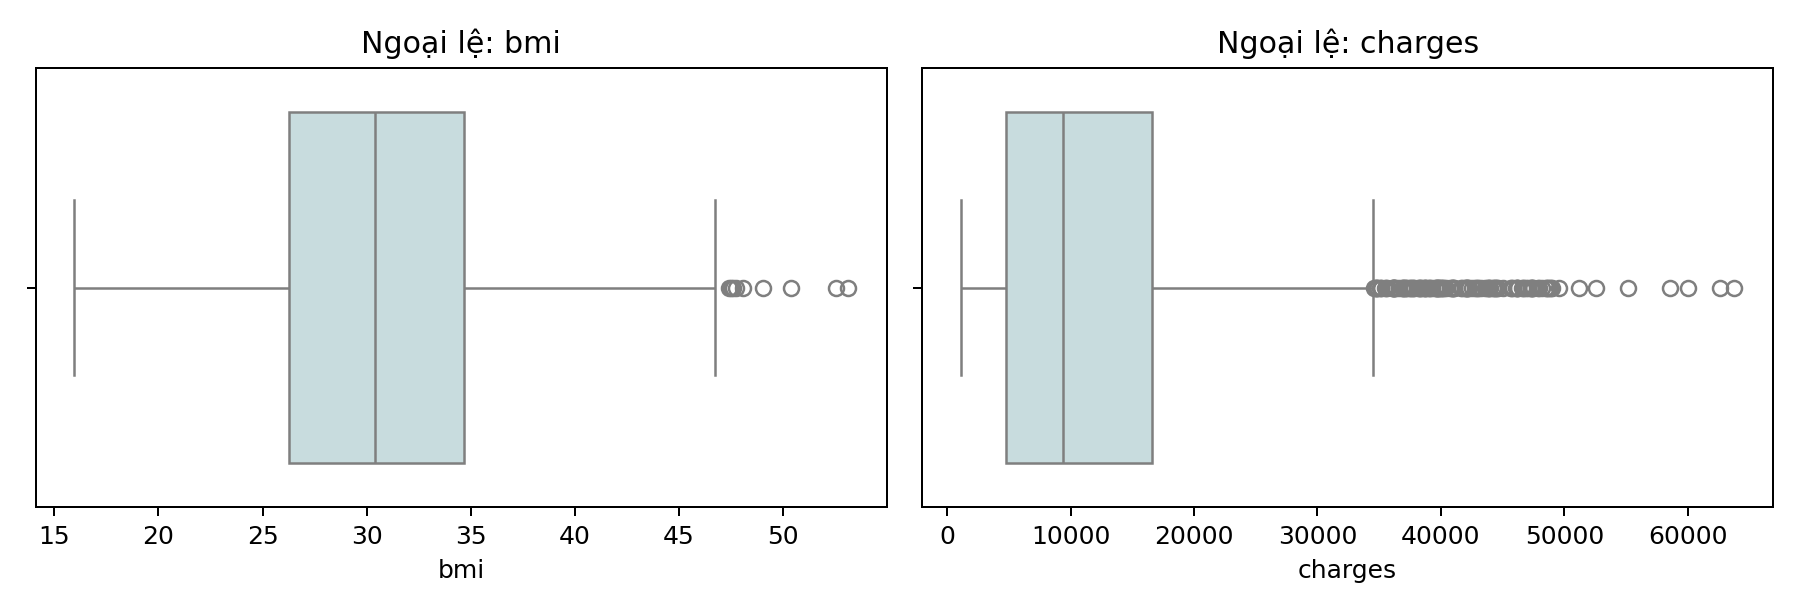

In [4]:
# Tính IQR cho biến định lượng; không áp dụng cho mã sex, smoker, region hoặc nhãn.
ngoai_le = []
for cot in ['age', 'bmi', 'children', 'charges']:
    q1 = df_goc[cot].describe()['25%']
    q3 = df_goc[cot].describe()['75%']
    iqr = q3 - q1
    duoi = q1 - 1.5 * iqr
    tren = q3 + 1.5 * iqr
    so_danh_dau = ((df_goc[cot] < duoi) | (df_goc[cot] > tren)).sum()
    ngoai_le.append([cot, q1, q3, iqr, duoi, tren, so_danh_dau])
ngoai_le = pd.DataFrame(ngoai_le, columns=['bien', 'Q1', 'Q3', 'IQR', 'nguong_duoi', 'nguong_tren', 'so_danh_dau'])
ngoai_le.to_csv('Bang03_Ngoai_le_IQR.csv', index=False)
print(ngoai_le.to_string(index=False))

# Vẽ bằng chứng ngoại lệ của BMI và chi phí trên dữ liệu gốc.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, cot in zip(axes, ['bmi', 'charges']):
    sns.boxplot(x=df_goc[cot], ax=ax, color='#c4dfe2')
    ax.set_title('Ngoại lệ: ' + cot)
    ax.set_xlabel(cot)
plt.tight_layout()
plt.savefig('Hinh01_Ngoai_le.png', dpi=180)
plt.show()
plt.close()

# Không điền thiếu vì dữ liệu không có ô thiếu; giữ các giá trị IQR đánh dấu.
# Bỏ đúng một dòng lặp hoàn toàn, trước khi chia tập huấn luyện và kiểm tra.
df = df_goc.drop_duplicates().copy()
df.to_csv('Insurance_clean.csv', index=False)
print('Kích thước sau xử lý:', df.shape)
print('Số dòng trùng còn lại:', df.duplicated().sum())


**Phân tích số liệu**

Trên 1.338 dòng gốc, quy tắc IQR đánh dấu 9 giá trị BMI và 139 giá trị charges; age và children không có giá trị vượt hàng rào IQR. Ngưỡng trên của BMI là 47,29 và của charges là 34.489,35. Đây là dấu hiệu để kiểm tra, chưa phải bằng chứng các quan sát bị nhập sai.

Boxplot của charges có đuôi phải dài và nhiều quan sát lớn. Việc xóa toàn bộ nhóm này có thể làm mất phần chi phí cao có ý nghĩa với bài toán bảo hiểm. Vì chưa có căn cứ xác định lỗi, phân tích chính giữ các quan sát được đánh dấu.


## 05 Phân bố nhãn và thống kê mô tả

Giai đoạn 3: xác định tỷ lệ hai nhãn và độ lệch phân phối. insuranceclaim=1 được hiểu là có yêu cầu theo tên nhãn, không đồng nghĩa đã được chi trả.


 nhan  so_ban_ghi  ty_le_phan_tram
    0         555        41.510845
    1         782        58.489155
           count          mean           std        min       25%        50%          75%          max
age       1337.0     39.222139     14.044333    18.0000    27.000    39.0000     51.00000     64.00000
bmi       1337.0     30.663452      6.100468    15.9600    26.290    30.4000     34.70000     53.13000
children  1337.0      1.095737      1.205571     0.0000     0.000     1.0000      2.00000      5.00000
charges   1337.0  13279.121487  12110.359656  1121.8739  4746.344  9386.1613  16657.71745  63770.42801


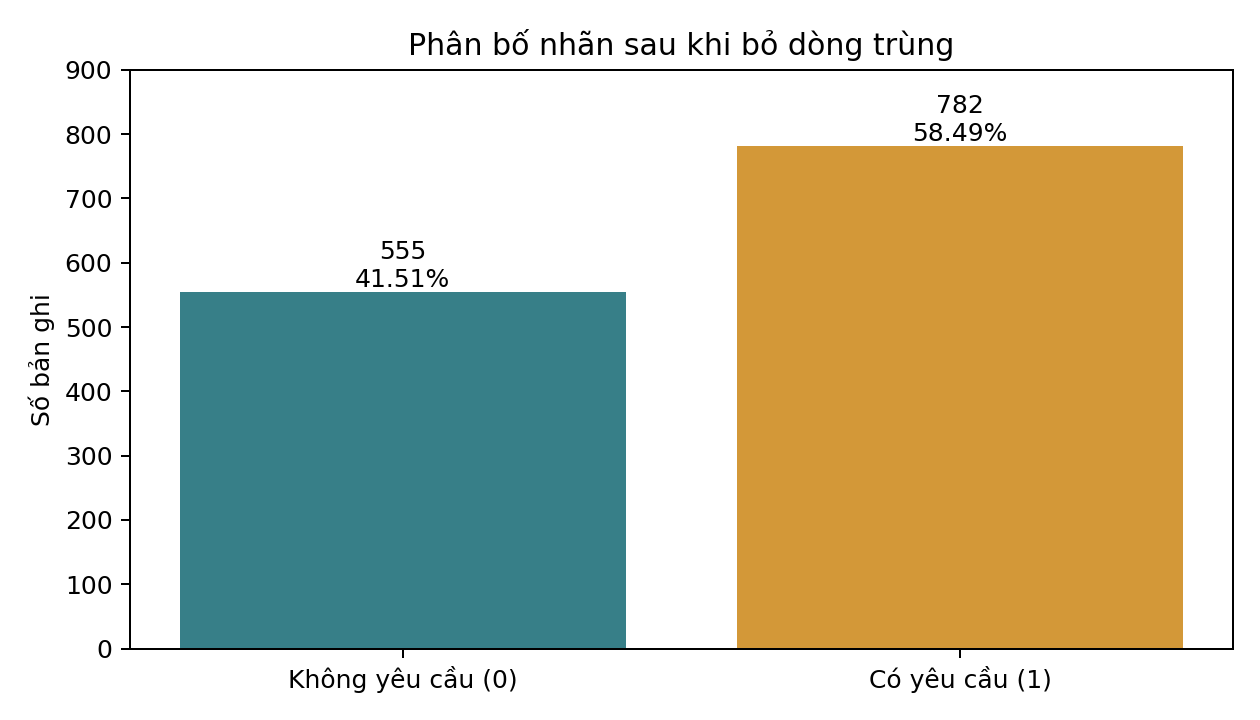

In [5]:
# Thống kê nhãn và các biến định lượng sau khi bỏ dòng trùng.
nhan = df['insuranceclaim'].value_counts().sort_index().rename_axis('nhan').reset_index(name='so_ban_ghi')
nhan['ty_le_phan_tram'] = nhan['so_ban_ghi'] / len(df) * 100
nhan.to_csv('Bang04_Phan_bo_nhan.csv', index=False)
mo_ta = df[['age', 'bmi', 'children', 'charges']].describe().T
mo_ta.to_csv('Bang05_Thong_ke_mo_ta.csv', index_label='bien')
print(nhan.to_string(index=False))
print(mo_ta.to_string())

# Vẽ cột phân bố nhãn, ghi rõ cả số lượng và tỷ lệ.
plt.figure(figsize=(7, 4))
bars = plt.bar(['Không yêu cầu (0)', 'Có yêu cầu (1)'], nhan['so_ban_ghi'], color=['#377f88', '#d39838'])
for bar, n, ty_le in zip(bars, nhan['so_ban_ghi'], nhan['ty_le_phan_tram']):
    plt.text(bar.get_x() + bar.get_width()/2, n + 8, f'{n}\n{ty_le:.2f}%', ha='center', color='black')
plt.ylim(0, 900)
plt.ylabel('Số bản ghi')
plt.title('Phân bố nhãn sau khi bỏ dòng trùng')
plt.tight_layout()
plt.savefig('Hinh02_Phan_bo_nhan.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Sau khi bỏ một dòng trùng, dữ liệu còn 1.337 bản ghi: 782 nhãn 1 (58,49%) và 555 nhãn 0 (41,51%). Nhãn 1 nhiều hơn nhưng dữ liệu vẫn có đủ hai lớp để chia train/test có phân tầng.

Trên tập test, cách luôn dự đoán nhãn 1 đã đạt accuracy 58,58%. Vì vậy, kết quả mô hình cần được đọc cùng precision, recall và ma trận nhầm lẫn; không chỉ nhìn accuracy.


## 06 Phân bố biến định lượng

Histogram giúp quan sát hình dạng của tuổi, BMI, số người phụ thuộc và charges. Đọc trung vị cùng trung bình khi chi phí lệch phải; không tự gán đơn vị tiền tệ.


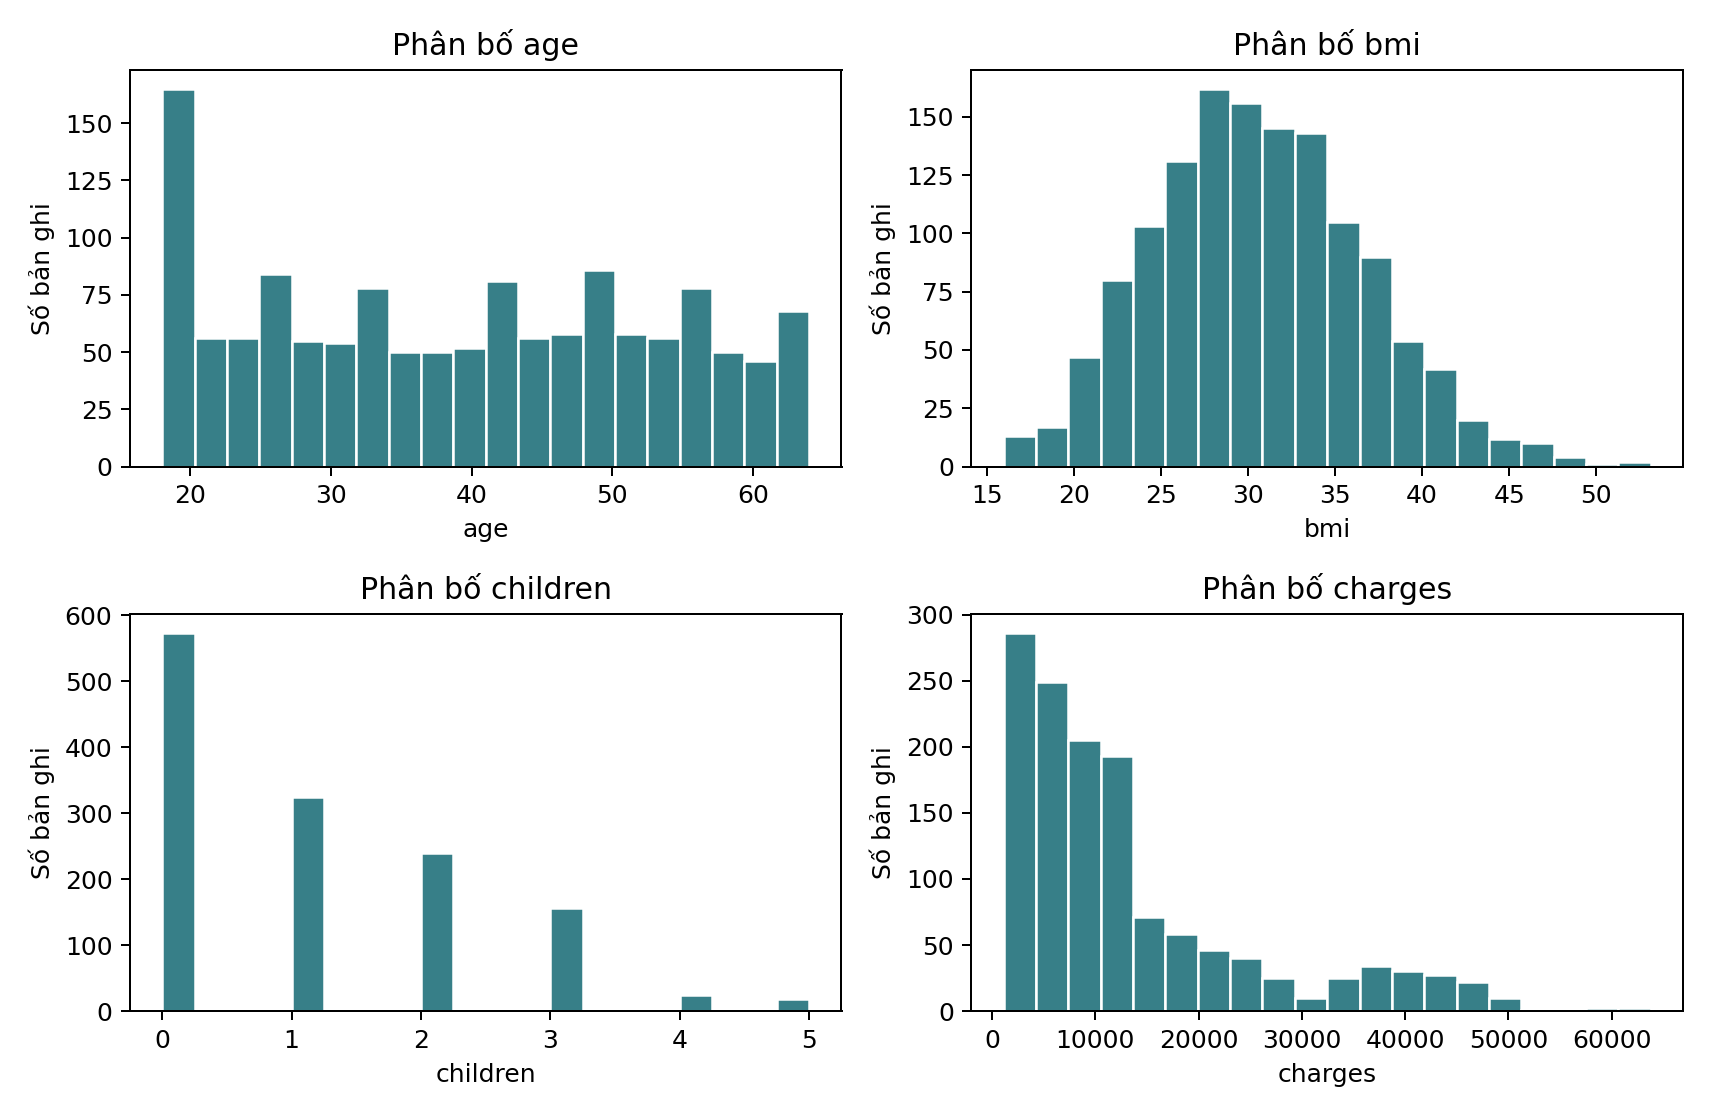

In [6]:
# Vẽ histogram của bốn biến định lượng, không thay đổi dữ liệu gốc.
fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.2))
for ax, cot in zip(axes.flat, ['age', 'bmi', 'children', 'charges']):
    ax.hist(df[cot], bins=20, color='#377f88', edgecolor='white')
    ax.set_title('Phân bố ' + cot)
    ax.set_xlabel(cot)
    ax.set_ylabel('Số bản ghi')
plt.tight_layout()
plt.savefig('Hinh03_Phan_bo_bien.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Tuổi nằm trong 18-64, trung vị 39; BMI có trung vị 30,40, nhỏ nhất 15,96 và lớn nhất 53,13. Tuổi tập trung tương đối nhiều ở nhóm trẻ, còn children là biến đếm từ 0 đến 5.

charges có trung bình 13.279,12 nhưng trung vị chỉ 9.386,16, cho thấy phân bố lệch phải. Một số chi phí cao kéo trung bình lên. Khi mô tả hồ sơ điển hình cần đọc cả trung vị, miền giá trị và hình dạng phân phối. Đơn vị tiền tệ và kỳ tính chi phí chưa được xác minh từ tài liệu đầu vào.


## 07 So sánh hút thuốc, tuổi, BMI và người phụ thuộc

Đối chiếu các giả định ban đầu bằng số lượng và tỷ lệ trong từng nhóm. Các khoảng tuổi/BMI là nhóm mô tả, không phải quy tắc chẩn đoán.



Theo smoker
 smoker  so_ban_ghi  so_nhan_1  ty_le_nhan_1
      0        1063        533     50.141110
      1         274        249     90.875912

Theo nhom_tuoi
nhom_tuoi  so_ban_ghi  so_nhan_1  ty_le_nhan_1
    18-29         416        238     57.211538
    30-44         392        184     46.938776
    45-64         529        360     68.052930

Theo nhom_bmi
nhom_bmi  so_ban_ghi  so_nhan_1  ty_le_nhan_1
     <25         245         48     19.591837
  25-<30         386        212     54.922280
  30-<35         390        268     68.717949
  35-<40         225        177     78.666667
    >=40          91         77     84.615385

Theo children
 children  so_ban_ghi  so_nhan_1  ty_le_nhan_1
        0         573        462     80.628272
        1         324        173     53.395062
        2         240         94     39.166667
        3         157         45     28.662420
        4          25          4     16.000000
        5          18          4     22.222222

Theo sex
 se

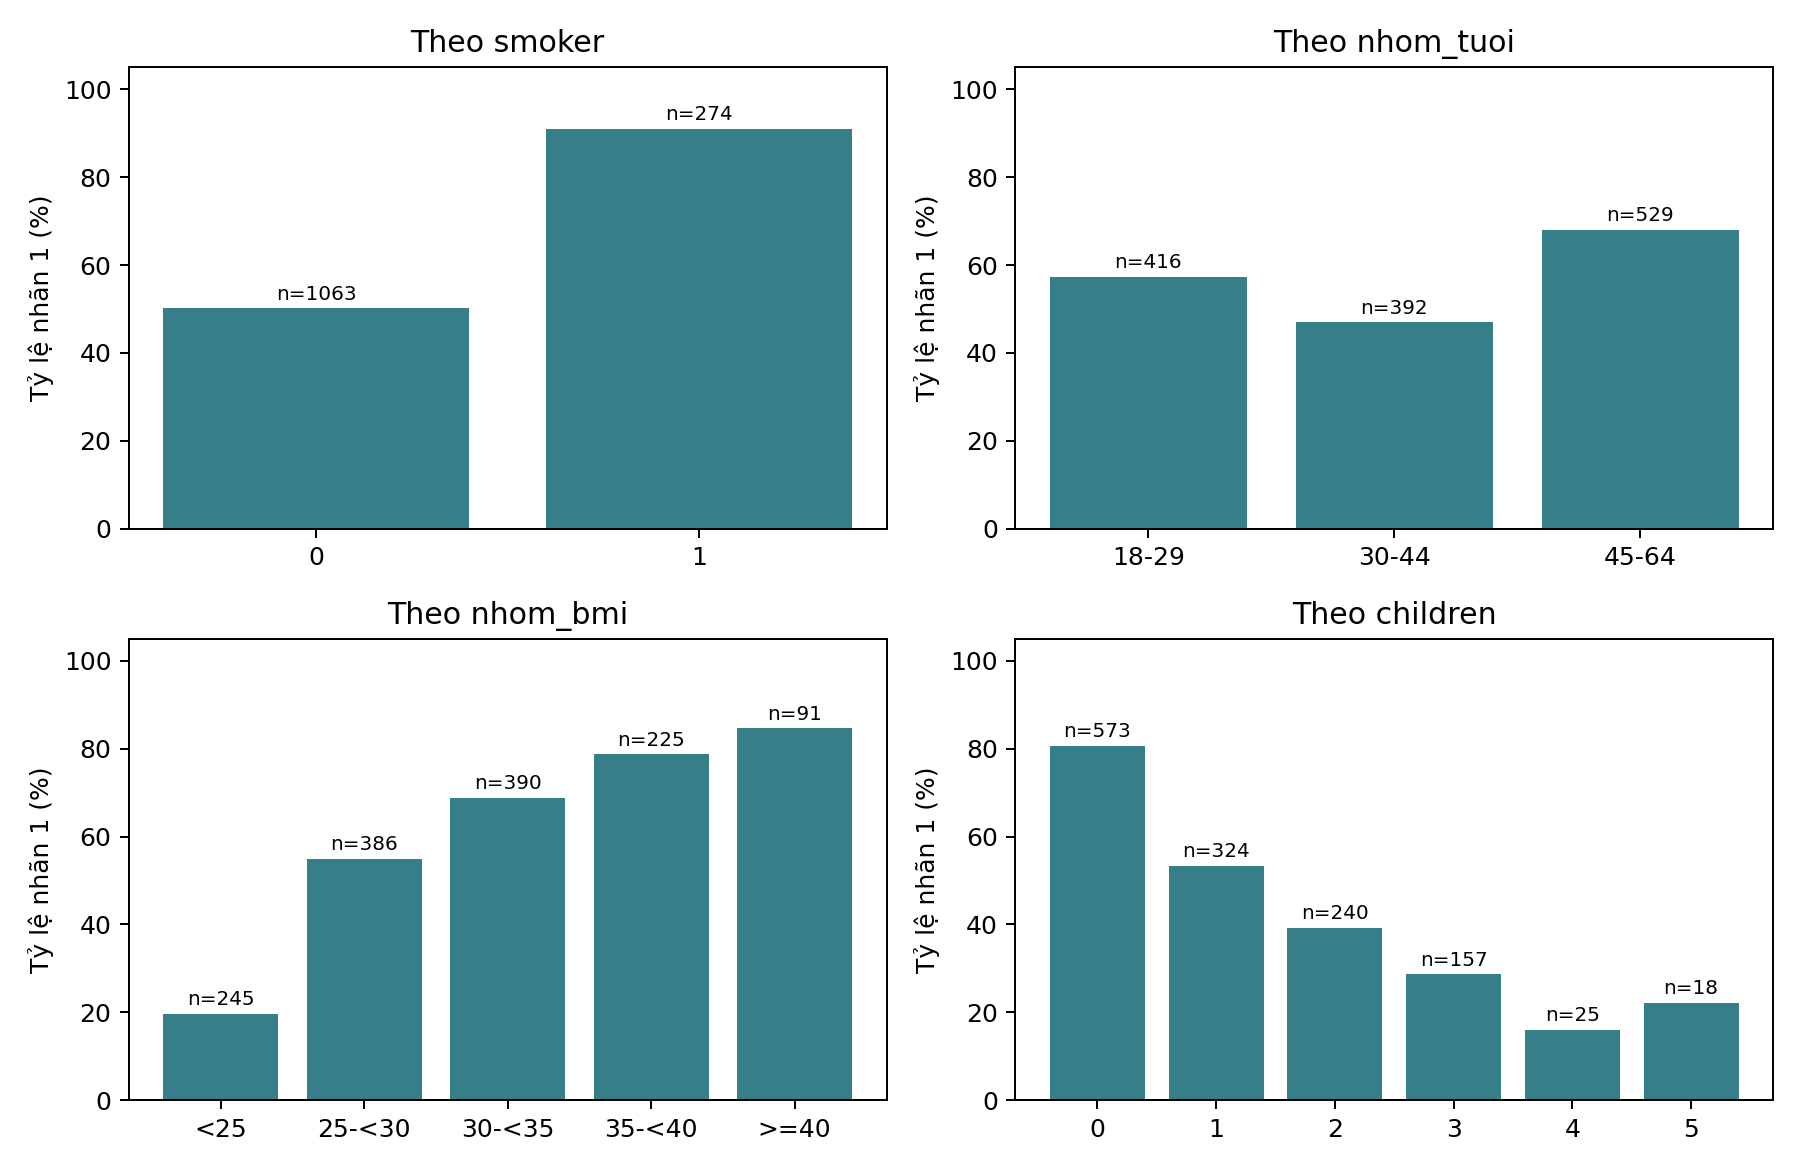

In [7]:
# Phân nhóm theo ngưỡng được xác định trước khi đọc kết quả so sánh.
df['nhom_tuoi'] = '45-64'
df.loc[df['age'] <= 29, 'nhom_tuoi'] = '18-29'
df.loc[(df['age'] >= 30) & (df['age'] <= 44), 'nhom_tuoi'] = '30-44'
df['nhom_bmi'] = '>=40'
df.loc[df['bmi'] < 25, 'nhom_bmi'] = '<25'
df.loc[(df['bmi'] >= 25) & (df['bmi'] < 30), 'nhom_bmi'] = '25-<30'
df.loc[(df['bmi'] >= 30) & (df['bmi'] < 35), 'nhom_bmi'] = '30-<35'
df.loc[(df['bmi'] >= 35) & (df['bmi'] < 40), 'nhom_bmi'] = '35-<40'

# Tóm tắt từng nhóm, luôn đọc tỷ lệ cùng với cỡ mẫu.
nhom = {}
for cot in ['smoker', 'nhom_tuoi', 'nhom_bmi', 'children', 'sex', 'region']:
    bang = df.groupby(cot, observed=True)['insuranceclaim'].agg(['count', 'sum', 'mean']).reset_index()
    bang.columns = [cot, 'so_ban_ghi', 'so_nhan_1', 'ty_le_nhan_1']
    if cot == 'nhom_bmi':
        bang = bang.set_index(cot).loc[['<25', '25-<30', '30-<35', '35-<40', '>=40']].reset_index()
    bang['ty_le_nhan_1'] = bang['ty_le_nhan_1'] * 100
    nhom[cot] = bang
    bang.to_csv('Bang06_Nhom_' + cot + '.csv', index=False)
    print('\nTheo', cot)
    print(bang.to_string(index=False))

# Vẽ tỷ lệ có nhãn 1 theo bốn đặc điểm; không dùng khoảng tin cậy ngoài tài liệu.
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, cot in zip(axes.flat, ['smoker', 'nhom_tuoi', 'nhom_bmi', 'children']):
    bang = nhom[cot]
    ax.bar(bang[cot].astype(str), bang['ty_le_nhan_1'], color='#377f88')
    ax.set_ylim(0, 105)
    ax.set_title('Theo ' + cot)
    ax.set_ylabel('Tỷ lệ nhãn 1 (%)')
    for i, n in enumerate(bang['so_ban_ghi']):
        ax.text(i, bang.iloc[i]['ty_le_nhan_1'] + 2, 'n=' + str(n), ha='center', fontsize=8, color='black')
plt.tight_layout()
plt.savefig('Hinh04_So_sanh_nhom.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Nhóm smoker=1 có 249/274 nhãn 1 (90,88%), so với 533/1063 (50,14%) ở nhóm smoker=0. Chênh lệch là 40,73 điểm phần trăm. Giả định về tỷ lệ cao hơn ở nhóm hút thuốc được số liệu mẫu ủng hộ.

Ba nhóm tuổi 18-29, 30-44 và 45-64 có tỷ lệ lần lượt 57,21%, 46,94% và 68,05%. Nhóm giữa có tỷ lệ thấp nhất; do đó giả định tỷ lệ tăng đều theo tuổi không phù hợp với cách phân nhóm này.

Tỷ lệ nhãn 1 tăng từ 19,59% ở BMI dưới 25 lên 84,62% ở BMI từ 40 trở lên. Các ngưỡng BMI chỉ phục vụ phân tích nhóm, không được dùng để chẩn đoán sức khỏe.

Nhóm children=0 có tỷ lệ 80,63%, trong khi children=3 đạt 28,66%. Tuy nhiên, nhóm children=4 và 5 chỉ có 25 và 18 quan sát; tỷ lệ tăng lại từ 16,00% lên 22,22%. Không nên suy ra một quy luật giảm tuyệt đối hoặc tác động bảo vệ của việc có thêm người phụ thuộc.


## 08 So sánh mã giới tính và vùng cư trú

So sánh sex và region theo đúng mã trong CSV. Chênh lệch tỷ lệ mô tả chưa chứng minh khác biệt của tổng thể hoặc quan hệ nhân quả.


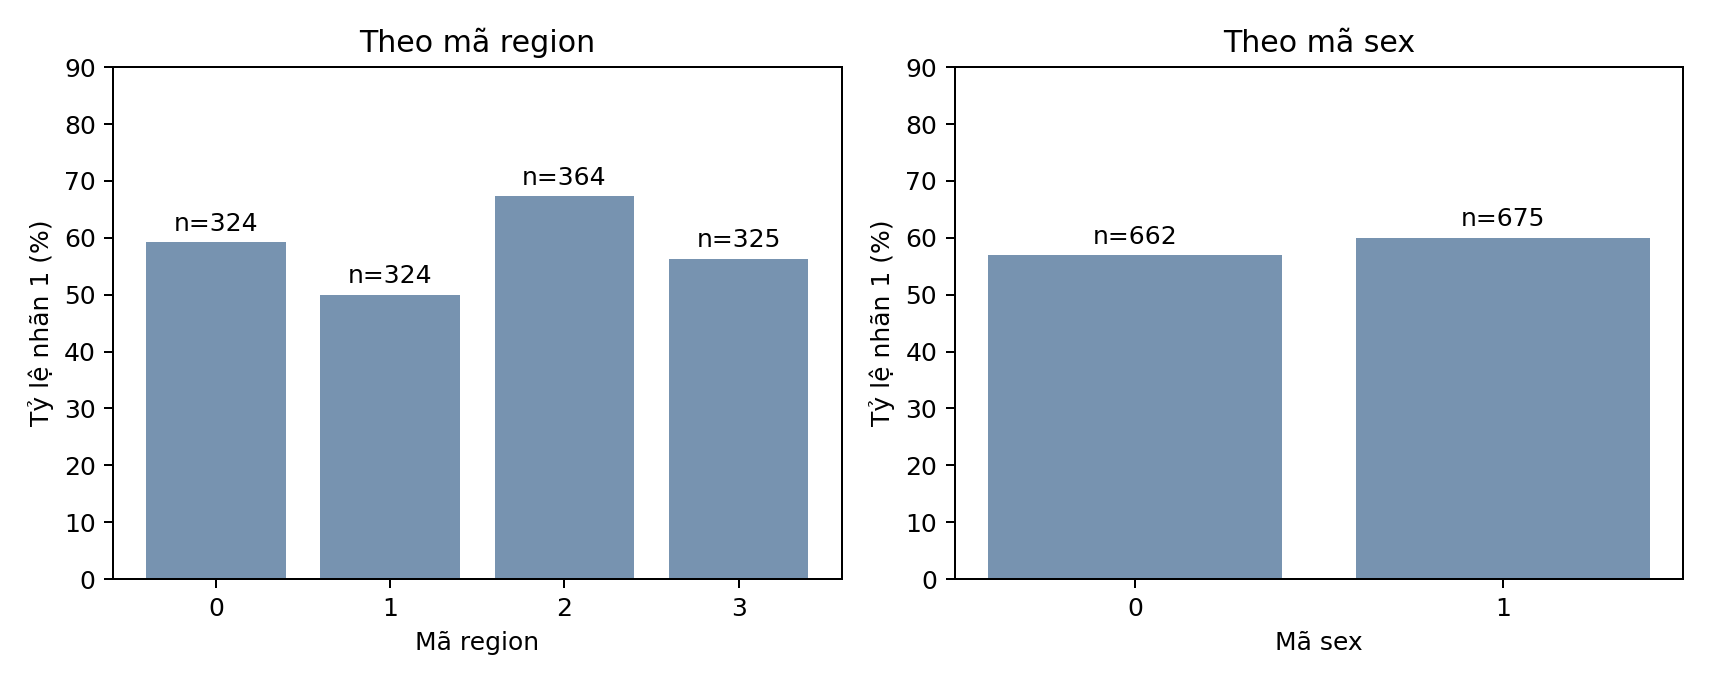

In [8]:
# So sánh nhóm sex và region bằng tỷ lệ, không coi mã region là số đo liên tục.
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, cot in zip(axes, ['region', 'sex']):
    bang = nhom[cot]
    ax.bar(bang[cot].astype(str), bang['ty_le_nhan_1'], color='#7793b0')
    ax.set_title('Theo mã ' + cot)
    ax.set_xlabel('Mã ' + cot)
    ax.set_ylim(0, 90)
    ax.set_ylabel('Tỷ lệ nhãn 1 (%)')
    for i, n in enumerate(bang['so_ban_ghi']):
        ax.text(i, bang.iloc[i]['ty_le_nhan_1'] + 2, 'n=' + str(n), ha='center', color='black')
plt.tight_layout()
plt.savefig('Hinh05_Vung_Gioi.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Mã region=2 có tỷ lệ cao nhất (67,31%), còn region=1 thấp nhất (50,00%). Chênh lệch có thể phản ánh cơ cấu tuổi, BMI hoặc hút thuốc khác nhau giữa các nhóm. Không dùng mã vùng như một thang đo số liên tục.

Nhóm sex=0 có 662 quan sát, tỷ lệ 56,95%; sex=1 có 675 quan sát, tỷ lệ 60,00%. Chênh lệch mô tả là 3,05 điểm phần trăm. Báo cáo chưa có kiểm định suy luận để kết luận khác biệt của tổng thể.


## 09 Chi phí y tế và thời điểm thông tin

Boxplot và scatter plot dùng để mô tả charges theo nhãn và theo BMI/hút thuốc. charges không được đưa vào mô hình dự đoán chính vì chưa rõ được biết trước hay sau yêu cầu bảo hiểm.


 insuranceclaim  count         mean       median
              0    555  8821.421892  6933.242250
              1    782 16442.834114 11552.360775


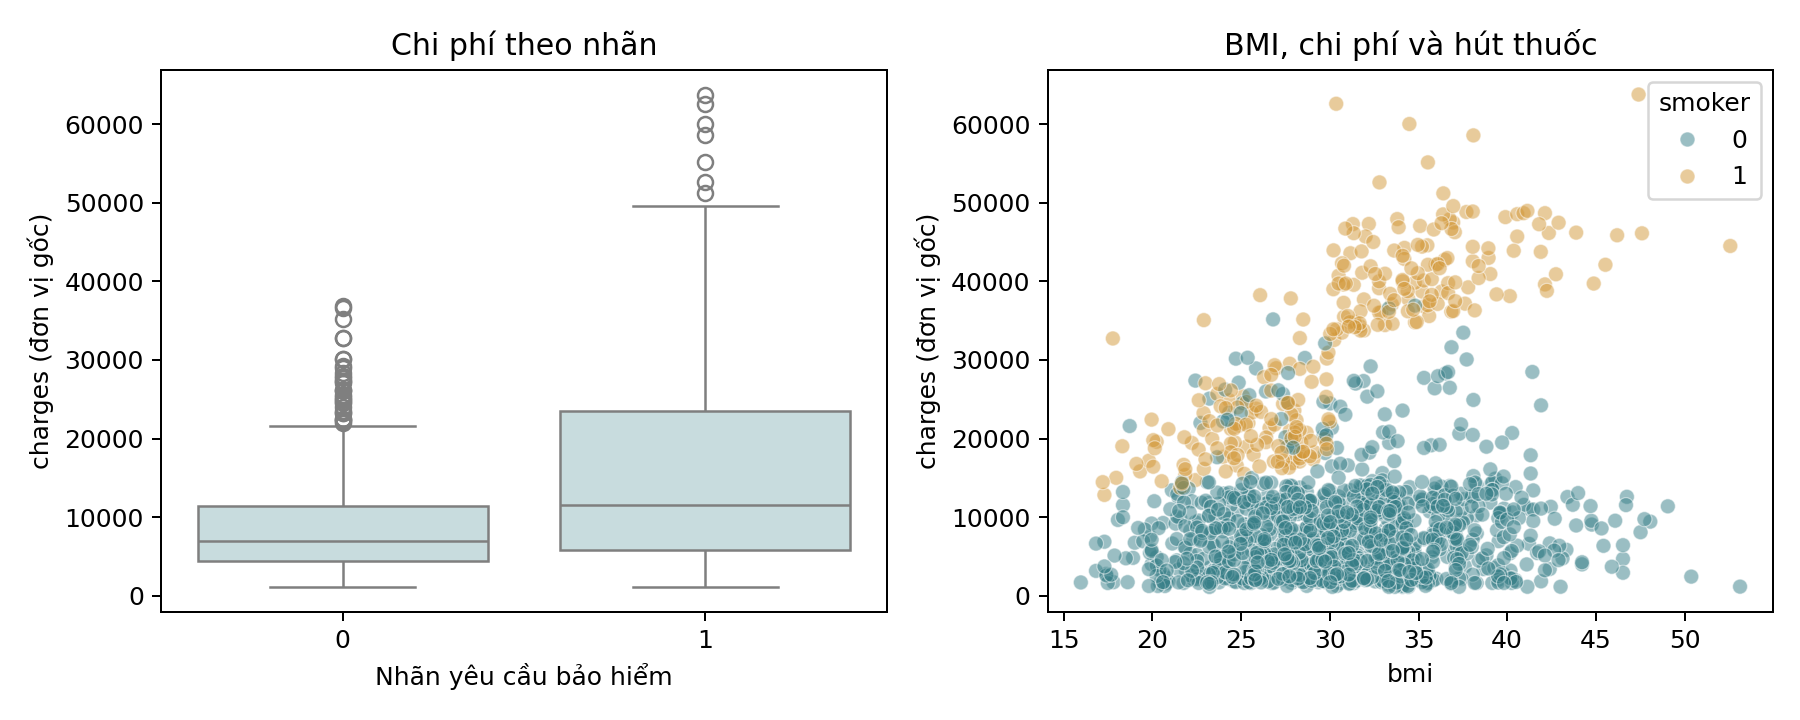

In [9]:
# Thống kê charges theo nhãn, giữ nguyên đơn vị gốc của CSV.
chi_phi = df.groupby('insuranceclaim')['charges'].agg(['count', 'mean', 'median']).reset_index()
chi_phi.to_csv('Bang07_Chi_phi_theo_nhan.csv', index=False)
print(chi_phi.to_string(index=False))

# Vẽ chi phí theo nhãn và quan hệ BMI-chi phí theo nhóm hút thuốc.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x='insuranceclaim', y='charges', color='#c4dfe2', ax=axes[0])
axes[0].set_title('Chi phí theo nhãn')
axes[0].set_xlabel('Nhãn yêu cầu bảo hiểm')
axes[0].set_ylabel('charges (đơn vị gốc)')
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.5,
                palette=['#377f88', '#d39838'], ax=axes[1])
axes[1].set_title('BMI, chi phí và hút thuốc')
axes[1].set_ylabel('charges (đơn vị gốc)')
plt.tight_layout()
plt.savefig('Hinh06_Chi_phi.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Trung vị charges của nhãn 1 là 11.552,36, cao hơn 6.933,24 của nhãn 0. Trung bình tương ứng là 16.442,83 và 8.821,42. Dù khác nhau về mức trung tâm, hai phân bố vẫn chồng lấn, nên một ngưỡng chi phí không phân tách hoàn toàn hai nhãn.

Scatter plot cho thấy quan hệ giữa BMI và chi phí khác nhau theo nhóm hút thuốc. Không nên diễn giải toàn bộ dữ liệu như một quan hệ tuyến tính duy nhất. charges được dùng để mô tả nhưng không đưa vào mô hình chính do bộ dữ liệu không cho biết chi phí được biết trước hay sau thời điểm phát sinh yêu cầu.


## 10 Quan sát mối liên hệ và đối chiếu giả định

Thực hiện phần “đối chiếu số liệu với các giả định ban đầu” theo đề. Sử dụng tỷ lệ nhóm, trung vị, scatter plot và boxplot; không suy luận ý nghĩa thống kê bằng p-value.


Hút thuốc: đọc tỷ lệ nhãn 1 của smoker=0 và smoker=1 trong Bang06_Nhom_smoker.csv.
Tuổi: so sánh ba nhóm 18-29, 30-44, 45-64; kiểm tra có tăng đều hay không.
BMI: so sánh tỷ lệ giữa các khoảng BMI và quan sát hai nhãn trên scatter plot.
Chi phí: đọc trung bình và trung vị theo nhãn trong Bang07_Chi_phi_theo_nhan.csv.
Các nhận xét chỉ áp dụng cho bộ dữ liệu đang phân tích; chưa phải kiểm định suy luận.


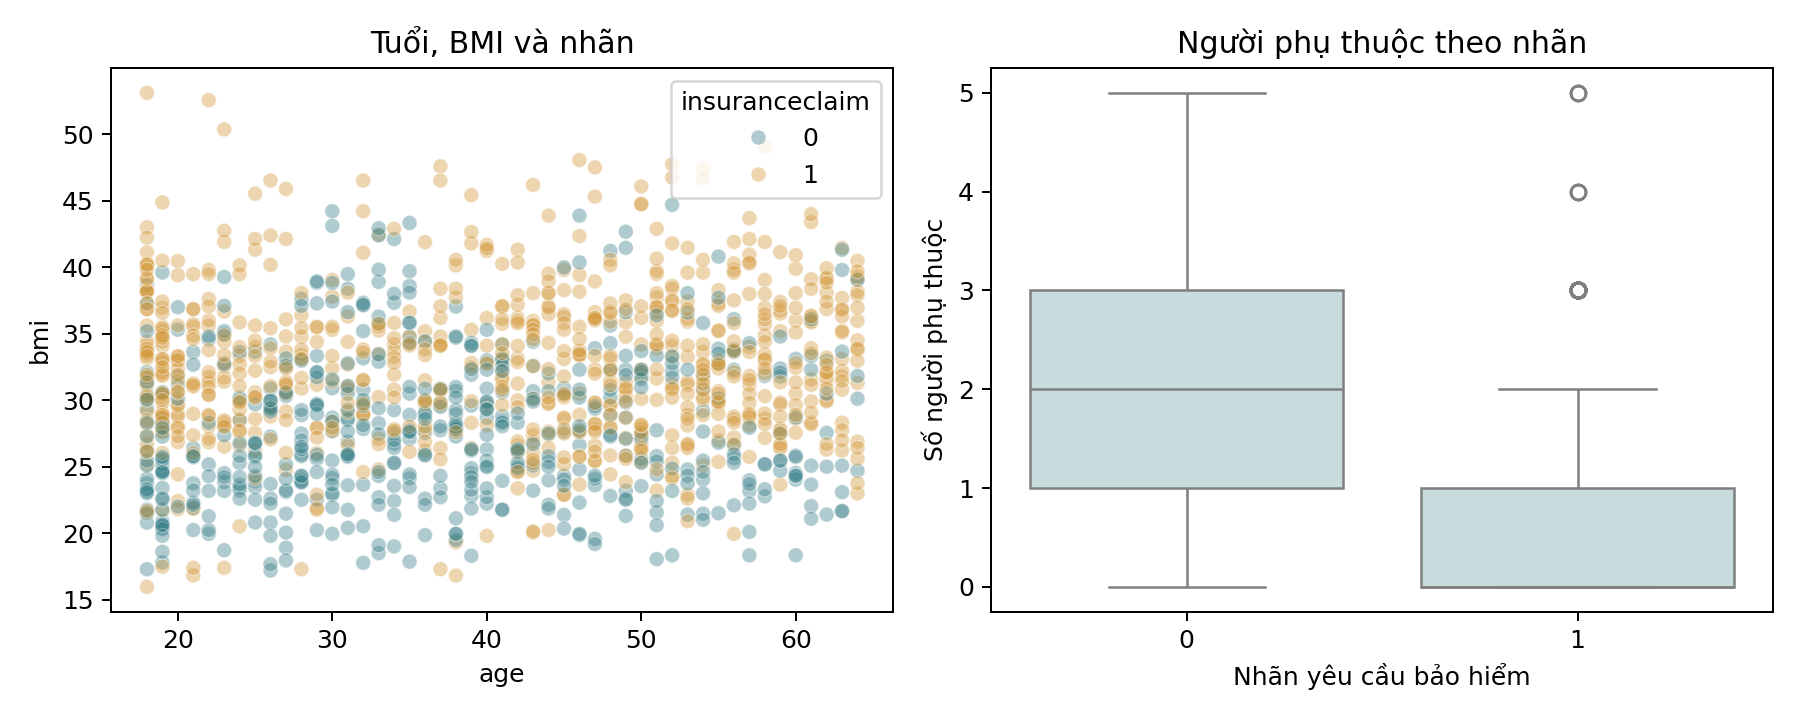

In [10]:
# Quan sát đồng thời tuổi, BMI và nhãn, rồi đọc phân bố số người phụ thuộc theo nhãn.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.scatterplot(data=df, x='age', y='bmi', hue='insuranceclaim', alpha=0.4,
                palette=['#377f88', '#d39838'], ax=axes[0])
axes[0].set_title('Tuổi, BMI và nhãn')
sns.boxplot(data=df, x='insuranceclaim', y='children', color='#c4dfe2', ax=axes[1])
axes[1].set_title('Người phụ thuộc theo nhãn')
axes[1].set_xlabel('Nhãn yêu cầu bảo hiểm')
axes[1].set_ylabel('Số người phụ thuộc')
plt.tight_layout()
plt.savefig('Hinh07_Moi_lien_he.png', dpi=180)
plt.show()
plt.close()

# Đối chiếu giả định bằng số liệu mô tả, không dùng kết luận bác bỏ H0.
print('Hút thuốc: đọc tỷ lệ nhãn 1 của smoker=0 và smoker=1 trong Bang06_Nhom_smoker.csv.')
print('Tuổi: so sánh ba nhóm 18-29, 30-44, 45-64; kiểm tra có tăng đều hay không.')
print('BMI: so sánh tỷ lệ giữa các khoảng BMI và quan sát hai nhãn trên scatter plot.')
print('Chi phí: đọc trung bình và trung vị theo nhãn trong Bang07_Chi_phi_theo_nhan.csv.')
print('Các nhận xét chỉ áp dụng cho bộ dữ liệu đang phân tích; chưa phải kiểm định suy luận.')


**Phân tích số liệu**

Scatter plot cho thấy hai nhãn xuất hiện ở nhiều nhóm tuổi và vẫn có vùng chồng lấn theo BMI. Vì vậy, không thể phân tách toàn bộ nhãn chỉ bằng một ngưỡng tuổi hoặc BMI. Nhận xét này cần được đọc cùng tỷ lệ theo nhóm ở Hình 4.

Boxplot cho thấy nhóm nhãn 1 tập trung ở số người phụ thuộc thấp hơn nhóm nhãn 0. Số liệu nhóm children=0 có tỷ lệ nhãn 1 là 80,63%, còn children=3 là 28,66%. Biểu đồ mô tả cấu trúc của mẫu, không chứng minh việc có thêm người phụ thuộc làm giảm yêu cầu bảo hiểm.


## 11 Mã hóa và chia tập dữ liệu

Mô hình dùng age, bmi, children, sex, smoker và region. Mã hóa one-hot region bằng get_dummies; chia 80/20 có phân tầng, rồi fit StandardScaler trên train và chỉ transform trên test.


In [11]:
# One-hot mã vùng vì các mã 0, 1, 2, 3 không có khoảng cách định lượng.
X = pd.get_dummies(df[['age', 'bmi', 'children', 'sex', 'smoker', 'region']],
                   columns=['region'], drop_first=True)
y = df['insuranceclaim']

# Chia phân tầng giống cách thực hành trong tài liệu tuần 15.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                 random_state=42, stratify=y)

# Chỉ học tham số chuẩn hóa từ train, tránh dùng thông tin của test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Các đặc trưng:', list(X.columns))
print('Tỷ lệ nhãn 1 trên test:', y_test.mean())


Train: (1069, 8) Test: (268, 8)
Các đặc trưng: ['age', 'bmi', 'children', 'sex', 'smoker', 'region_1', 'region_2', 'region_3']
Tỷ lệ nhãn 1 trên test: 0.585820895522388


## 12 Huấn luyện và so sánh bốn mô hình

Dùng tham số trong bài thực hành tuần 15: Logistic Regression, KNN k=5, cây sâu 3, Random Forest 10 cây. Precision và recall được tính cho nhãn 1. Tập test dùng để mô tả hiệu suất, không dùng để chỉnh tham số.


In [12]:
# Khởi tạo đúng bốn mô hình cơ bản và các tham số minh họa của tuần 15.
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=10, random_state=42)
}

# Đánh giá cùng một cách chia để các điểm số có thể so sánh.
ket_qua = []
du_doan = pd.DataFrame({'chi_so_dong': y_test.index, 'nhan_thuc_te': y_test.values})
ma_tran = {}
for ten, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred_train = model.predict(X_train_scaled)
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    acc_train = accuracy_score(y_train, pred_train)
    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, pos_label=1)
    rec = recall_score(y_test, pred, pos_label=1)
    auc = roc_auc_score(y_test, proba)
    ket_qua.append([ten, acc_train, acc, prec, rec, auc])
    du_doan[ten] = pred
    ma_tran[ten] = confusion_matrix(y_test, pred)
    pd.DataFrame(ma_tran[ten], index=['Thuc_te_0', 'Thuc_te_1'],
                 columns=['Du_doan_0', 'Du_doan_1']).to_csv('Ma_tran_' + ten.replace(' ', '_') + '.csv')
ket_qua = pd.DataFrame(ket_qua, columns=['mo_hinh', 'accuracy_train', 'accuracy_test', 'precision_1', 'recall_1', 'roc_auc'])
ket_qua.to_csv('Bang09_Ket_qua_mo_hinh.csv', index=False)
du_doan.to_csv('Bang10_Du_doan_test.csv', index=False)
print(ket_qua.to_string(index=False))
print('Mốc luôn dự đoán nhãn 1 trên test:', y_test.mean())


            mo_hinh  accuracy_train  accuracy_test  precision_1  recall_1  roc_auc
Logistic Regression        0.896165       0.861940     0.870370  0.898089 0.904860
                KNN        0.924228       0.869403     0.876543  0.904459 0.950852
      Decision Tree        0.853134       0.832090     0.982759  0.726115 0.915849
      Random Forest        1.000000       0.921642     0.978873  0.885350 0.984937
Mốc luôn dự đoán nhãn 1 trên test: 0.585820895522388


## 13 Ma trận nhầm lẫn

Ma trận cho biết dự đoán đúng/sai theo từng nhãn. Hàng là thực tế, cột là dự đoán; đọc TN, FP, FN, TP theo thứ tự các ô. Chữ trên hình và trong bảng đều màu đen.


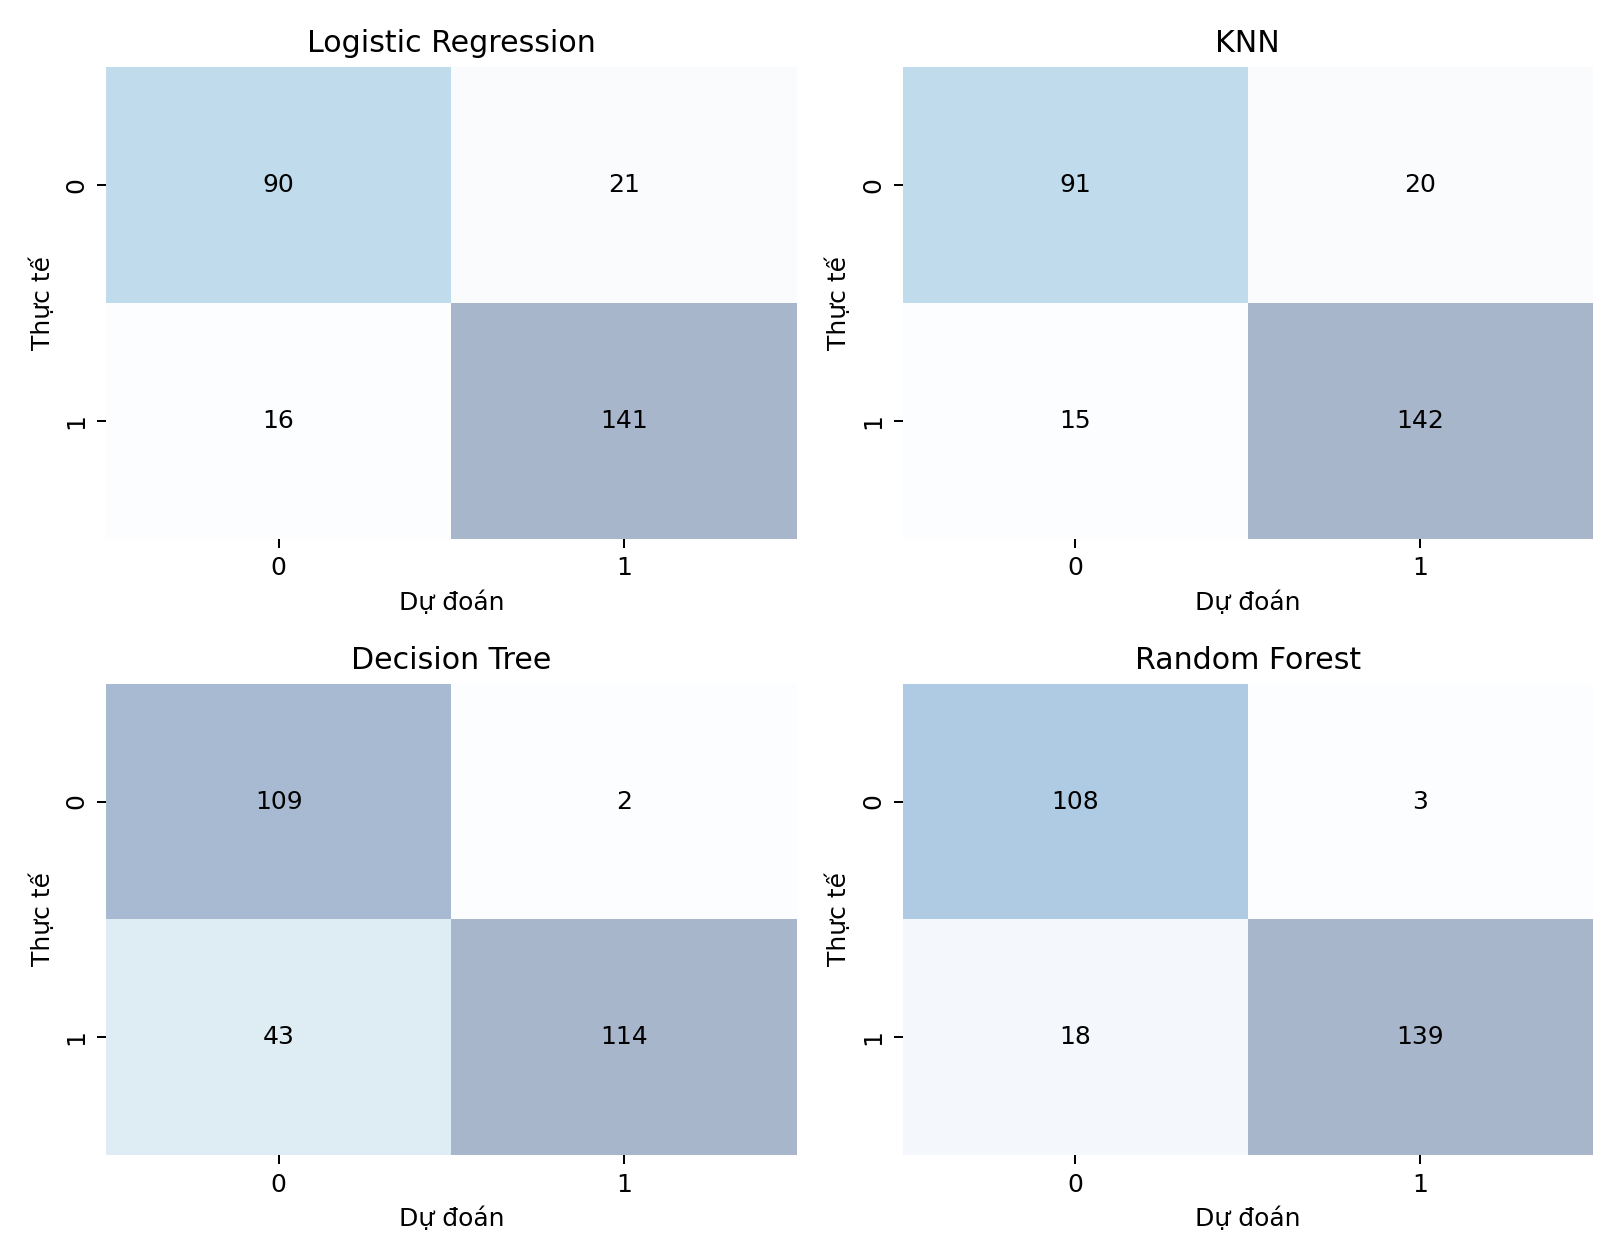

In [13]:
# Hiển thị đủ bốn ma trận để thấy đánh đổi giữa bỏ sót và dự đoán nhầm.
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, (ten, bang) in zip(axes.flat, ma_tran.items()):
    sns.heatmap(bang, annot=True, fmt='d', cmap='Blues', alpha=0.35,
                annot_kws={'color': 'black'}, cbar=False, ax=ax,
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    ax.set_title(ten)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')
plt.tight_layout()
plt.savefig('Hinh08_Ma_tran_nham_lan.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Hàng của mỗi ma trận là nhãn thực tế, cột là nhãn dự đoán. Với Random Forest, TN=108, FP=3, FN=18 và TP=139: mô hình dự đoán đúng 247/268 trường hợp nhưng vẫn bỏ sót 18 nhãn 1. Logistic Regression bỏ sót 16, KNN bỏ sót 15, còn cây sâu 3 bỏ sót 43.

Decision Tree có precision nhãn 1 cao (98,28%) nhưng recall chỉ 72,61%, cho thấy ít dự đoán nhầm nhãn 1 song bỏ sót nhiều trường hợp. KNN có recall 90,45% nhưng dự đoán nhầm 20 nhãn 0. Lựa chọn mô hình cho nghiệp vụ cần biết chi phí của FP và FN, chưa thể chỉ dựa vào một điểm số.


## 14 Đường cong ROC và AUC

Vẽ ROC của cả bốn mô hình theo ví dụ tuần 15. AUC mô tả khả năng xếp hạng trên test nội bộ; không quy đổi trực tiếp thành hiệu quả tài chính.


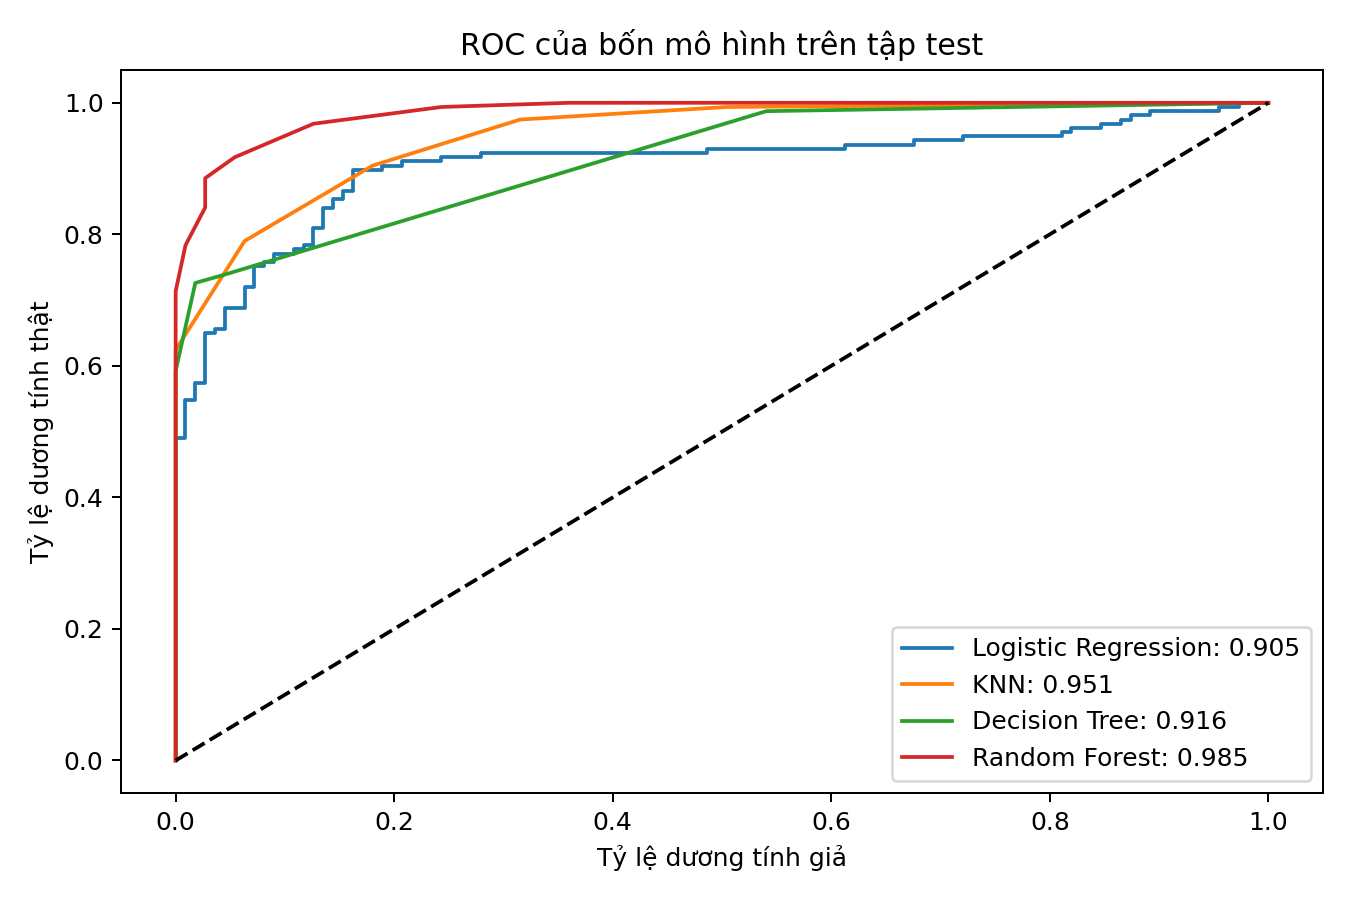

In [14]:
# Vẽ ROC trên cùng tập kiểm tra, giữ nguyên mô hình đã huấn luyện.
plt.figure(figsize=(7.5, 5))
for ten, model in models.items():
    proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{ten}: {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('Tỷ lệ dương tính giả')
plt.ylabel('Tỷ lệ dương tính thật')
plt.title('ROC của bốn mô hình trên tập test')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('Hinh09_ROC.png', dpi=180)
plt.show()
plt.close()


**Phân tích số liệu**

Random Forest đạt ROC-AUC 0,9849, cao nhất trong bốn mô hình ở lần chia này; KNN đạt 0,9509 và cây sâu 3 đạt 0,9158. Đường chéo thể hiện mốc xếp hạng ngẫu nhiên. AUC phản ánh khả năng xếp hạng theo xác suất, khác với accuracy tại ngưỡng dự đoán mặc định.

Random Forest đạt accuracy train 100% nhưng accuracy test 92,16%. Khoảng cách này cho thấy cần thận trọng về khả năng khái quát hóa. Kết quả chỉ là so sánh nội bộ với một lần chia train/test, chưa xác nhận mô hình tốt nhất trên dữ liệu bảo hiểm độc lập.


## 15 Tổng hợp phát hiện và kiểm tra đầu ra

Giai đoạn 4: đọc các tỷ lệ, cỡ mẫu và sai số dự đoán để đưa ra khuyến nghị. Cần dữ liệu bảo hiểm độc lập, định danh và dấu thời gian trước khi cân nhắc áp dụng nghiệp vụ.


In [15]:
# Tổng hợp các phát hiện chính bằng số liệu vừa tính, không dùng số từ phiên bản cũ.
print('Gốc:', len(df_goc), 'Sau bỏ trùng:', len(df))
print('Không có nhãn yêu cầu:', (df['insuranceclaim'] == 0).sum())
print('Có nhãn yêu cầu:', (df['insuranceclaim'] == 1).sum())
print('Tỷ lệ theo hút thuốc:')
print(nhom['smoker'].to_string(index=False))
print('Kết quả mô hình:')
print(ket_qua.to_string(index=False))

# Nêu phạm vi ứng dụng và giới hạn của dữ liệu.
print('Khuyến nghị: chuẩn hóa thông tin hồ sơ, xác minh nhãn và thời điểm quan sát.')
print('Chỉ xem mô hình là thử nghiệm hỗ trợ; chưa dùng để tự động quyết định bồi thường hoặc mức phí.')
print('Các bảng và chín hình đã được lưu trong thư mục làm việc hiện tại.')


Gốc: 1338 Sau bỏ trùng: 1337
Không có nhãn yêu cầu: 555
Có nhãn yêu cầu: 782
Tỷ lệ theo hút thuốc:
 smoker  so_ban_ghi  so_nhan_1  ty_le_nhan_1
      0        1063        533     50.141110
      1         274        249     90.875912
Kết quả mô hình:
            mo_hinh  accuracy_train  accuracy_test  precision_1  recall_1  roc_auc
Logistic Regression        0.896165       0.861940     0.870370  0.898089 0.904860
                KNN        0.924228       0.869403     0.876543  0.904459 0.950852
      Decision Tree        0.853134       0.832090     0.982759  0.726115 0.915849
      Random Forest        1.000000       0.921642     0.978873  0.885350 0.984937
Khuyến nghị: chuẩn hóa thông tin hồ sơ, xác minh nhãn và thời điểm quan sát.
Chỉ xem mô hình là thử nghiệm hỗ trợ; chưa dùng để tự động quyết định bồi thường hoặc mức phí.
Các bảng và chín hình đã được lưu trong thư mục làm việc hiện tại.
